# 부산 신항 선석 통합운영 시뮬레이션 4차 (2025)

**4차 추가 내용**: (1) 반복 100회와 불확실성 구간(반복 분포, 연결선 단위 군집 부트스트랩), (2) 상반기로 배우고 하반기로 시험하는 검증과 선별 기준 고도화 시도.

- 셀 1~28: 데이터, 시뮬레이션, A/B/C 비교, 환적 연결, KPI 산식 (2·3차와 동일)
- 셀 29: 목표값(1·3·5·10·15·20·25·30%)과 산식 상한 (3차와 동일)
- 셀 30: 연결선 앞당김 시뮬레이션 100회와 95% 구간, KPI-6 보수 판정
- 셀 31: 상반기 학습 → 하반기 검증, 순위 방식 비교
- 셀 32: 요약 그림


In [1]:
#셀 1: 라이브러리와 경로 설정

import pandas as pd                          # 표(데이터프레임) 처리 라이브러리
import numpy as np                           # 숫자 계산 라이브러리
from pathlib import Path                     # 폴더·파일 경로를 다루는 도구

BASE = Path(".")                             # 노트북이 있는 폴더(프로젝트 최상위)를 기준으로 삼는다
BERTH_DIR = BASE / "data" / "berth"          # 터미널별 선석배정 파일 폴더
CONTAINER_DIR = BASE / "data" / "container"  # 컨테이너 반입·반출 파일 폴더
PORTMIS_DIR = BASE / "data" / "portmis"      # 포트미스 입출항 파일 폴더
VESSEL_DIR = BASE / "data" / "vessel"        # 선박 제원 파일 폴더
OUT_DIR = BASE / "output"                    # 결과를 저장할 폴더
OUT_DIR.mkdir(exist_ok=True)                 # output 폴더가 없으면 만든다

YEAR = 2025                                  # 분석할 연도

pd.set_option("display.width", 200)          # 표를 출력할 때 한 줄 너비를 넓힌다
pd.set_option("display.max_columns", 50)     # 열이 생략되지 않게 표시할 최대 열 수를 늘린다

for folder in [BERTH_DIR, CONTAINER_DIR, PORTMIS_DIR, VESSEL_DIR]:
    print(folder, "->", sorted(p.name for p in folder.iterdir()))

data/berth -> ['BCT_2025.xlsx', 'BNCT_2025.xlsx', 'DGT_2025.xlsx', 'HJNC_2025.xlsx', 'HPNT_2025.xls', 'PNC_2025.xlsx', 'PNIT_2025.xls']
data/container -> ['DGT_DGT.csv', 'DGT_HJNC_2025.csv', 'hjnc_hjnc.csv']
data/portmis -> ['portmis_calls.csv']
data/vessel -> ['vessel_spec_선박크기.csv']


In [2]:
# 셀 2: HJNC 선석배정 파일 읽기
hjnc_file = [p for p in BERTH_DIR.glob("*.xls*")      # berth 폴더의 엑셀 파일 중에서
             if "HJNC" in p.name.upper()]             # 이름에 HJNC가 들어간 파일을 찾는다
print(hjnc_file)                                      # 정확히 1개가 나와야 한다

hjnc_raw = pd.read_excel(hjnc_file[0], header=1)
print(hjnc_raw.shape)
print(hjnc_raw.columns.tolist())
hjnc_raw.head()

[PosixPath('data/berth/HJNC_2025.xlsx')]
(1002, 18)
['No', '선석', '항로', '모선항차', '선박명', '선사항차', '접안', '선사', '반입 시작일시', '반입 마감일시', '입항일시', '출항일시', '작업 시작일시', '작업 완료일시', '양하', '선적', 'S/H', '전배']
   No  선석    항로            모선항차                 선박명           선사항차 접안   선사           반입 시작일시           반입 마감일시              입항일시              출항일시           작업 시작일시           작업 완료일시    양하    선적  \
0   1  1B   MD3  YWDM-2024-0002           YM WISDOM      020W-021W  S  YML  2024-12-28 00:00  2024-12-31 06:00  2024-12-31 15:54  2025-01-02 23:00  2024-12-31 17:30  2025-01-02 21:46  3122  1276   
1   2  1B  SIS2  ZGHZ-2025-0001  ZHONG GU HANG ZHOU  24005W-24005W  S  TSL  2024-12-31 00:00  2025-01-02 15:00  2025-01-03 00:55  2025-01-03 22:00  2025-01-03 14:10  2025-01-03 21:42   807   514   
2   3  1B   JVH  OSWR-2025-0001   SWAN RIVER BRIDGE      105S-105S  S  ONE  2025-01-01 00:00  2025-01-03 14:00  2025-01-04 00:05  2025-01-04 11:00  2025-01-04 00:53  2025-01-04 10:59   252   444   
3   4  1B   AIS  

In [3]:
# 셀 3: 변환 도구 함수
def num(s):
    """쉼표·공백·'-'가 섞인 열을 숫자로 바꾼다. 바꿀 수 없는 값은 빈 값(NaN)이 된다."""
    cleaned = (s.astype(str)                          # 우선 모두 문자열로 바꾸고
                .str.replace(",", "")                 # 천 단위 쉼표를 없애고
                .str.strip()                          # 앞뒤 공백을 지우고
                .replace({"null": None, "-": None, "nan": None}))   # 값이 없다는 뜻의 글자는 빈 값으로
    return pd.to_numeric(cleaned, errors="coerce")    # 숫자로 변환 (실패하면 NaN)


def dt(s):
    """문자열 열을 날짜·시각으로 바꾼다. 바꿀 수 없는 값은 빈 값(NaT)이 된다."""
    return pd.to_datetime(s.replace({"-": None, "null": None}), errors="coerce")

In [4]:
# 셀 4: HJNC를 공통 형식으로 변환
def load_hjnc(raw):
    """HJNC 원본 표를 공통 열 이름의 표로 바꾼다."""
    return pd.DataFrame({
        "terminal": "HJNC",                           # 터미널 이름 (모든 행에 같은 값)
        "berth": raw["선석"].astype(str),              # 선석 번호
        "vessel": raw["선박명"],                       # 선박 이름
        "voyage": raw["모선항차"],                     # 모선 항차
        "carrier": raw["선사"],                        # 선사
        "route": raw["항로"],                          # 항로
        "gate_open": dt(raw["반입 시작일시"]),         # 컨테이너 반입 시작(게이트 오픈) 시각
        "gate_cutoff": dt(raw["반입 마감일시"]),       # 반입 마감 시각
        "etb": dt(raw["입항일시"]),                    # 접안 시각 (HJNC는 '입항일시' 열이 접안 시각)
        "etd": dt(raw["출항일시"]),                    # 출항 시각
        "work_start": dt(raw["작업 시작일시"]),        # 하역 작업 시작
        "work_end": dt(raw["작업 완료일시"]),          # 하역 작업 완료
        "discharge": num(raw["양하"]),                 # 양하(내리는) 수량
        "load": num(raw["선적"]),                      # 적하(싣는) 수량
        "shift": num(raw["S/H"]),                      # 선내 이동(shift) 수량
        "status": None,                               # HJNC에는 상태 열이 없다
    })

hjnc = load_hjnc(hjnc_raw)                            # 변환 실행
print(hjnc.shape)                                     # 행 수 확인
print(hjnc.dtypes)                                    # 각 열이 날짜·숫자로 잘 바뀌었는지 확인
print(hjnc[["etb", "etd"]].isna().sum())              # 접안·출항 시각이 비어 있는 행 수 (0에 가까워야 한다)
print(hjnc["etb"].min(), "~", hjnc["etb"].max())      # 접안 시각의 범위 (2025년이어야 한다)
hjnc.head()

(1002, 16)
terminal                  str
berth                     str
vessel                    str
voyage                    str
carrier                   str
route                     str
gate_open      datetime64[us]
gate_cutoff    datetime64[us]
etb            datetime64[us]
etd            datetime64[us]
work_start     datetime64[us]
work_end       datetime64[us]
discharge               int64
load                    int64
shift                   int64
status                 object
dtype: object
etb    0
etd    0
dtype: int64
2024-12-30 22:30:00 ~ 2025-12-31 08:40:00
  terminal berth              vessel          voyage carrier route  gate_open         gate_cutoff                 etb                 etd          work_start            work_end  discharge  load  \
0     HJNC    1B           YM WISDOM  YWDM-2024-0002     YML   MD3 2024-12-28 2024-12-31 06:00:00 2024-12-31 15:54:00 2025-01-02 23:00:00 2024-12-31 17:30:00 2025-01-02 21:46:00       3122  1276   
1     HJNC    1B  ZHONG GU

In [5]:
# 셀 5: HPNT, PNIT (HTML 형식의 .xls)
import io                                             # 문자열을 파일처럼 다루는 도구

def find_one(keyword):
    """berth 폴더에서 이름에 keyword가 들어간 파일을 정확히 하나 찾는다."""
    hits = [p for p in BERTH_DIR.glob("*.xls*") if keyword.upper() in p.name.upper()]
    assert len(hits) == 1, f"{keyword} 파일이 {len(hits)}개: {hits}"   # 0개나 2개 이상이면 멈춘다
    return hits[0]

def read_html_table(path):
    """확장자는 .xls지만 내용은 HTML 표인 파일에서 가장 큰 표를 읽는다."""
    text = open(path, encoding="utf-8").read()        # 파일을 글자로 읽는다
    tables = pd.read_html(io.StringIO(text), flavor="lxml")   # HTML 안의 표를 모두 찾아서
    return max(tables, key=len)                       # 행이 가장 많은 표를 고른다

hpnt_raw = read_html_table(find_one("HPNT"))          # HPNT 원본
pnit_raw = read_html_table(find_one("PNIT"))          # PNIT 원본
print("HPNT", hpnt_raw.shape, hpnt_raw.columns.tolist())   # 크기와 열 이름 확인
print("PNIT", pnit_raw.shape, pnit_raw.columns.tolist())


def load_hpnt(raw):
    return pd.DataFrame({
        "terminal": "HPNT", "berth": raw["선석"].astype(str), "vessel": raw["선명"], "voyage": raw["모선항차"],
        "carrier": raw["선사"], "route": raw["ROUTE"],
        "gate_open": dt(raw["반입시작일시"]), "gate_cutoff": dt(raw["반입마감시한"]),
        "etb": dt(raw["접안(예정)일시"]), "etd": dt(raw["출항(예정)일시"]),   # 접안·출항 시각
        "work_start": pd.NaT, "work_end": pd.NaT,     # HPNT에는 작업 시각 열이 없다
        "discharge": num(raw["양하"]), "load": num(raw["적하"]), "shift": num(raw["Shift"]),
        "status": raw["상태"]})

def load_pnit(raw):
    return pd.DataFrame({
        "terminal": "PNIT", "berth": raw["선석"].astype(str), "vessel": raw["선명"], "voyage": raw["모선항차"],
        "carrier": raw["선사"], "route": raw["ROUTE"],
        "gate_open": pd.NaT,                          # PNIT에는 반입 시작 열이 없다
        "gate_cutoff": dt(raw["반입마감시한"]),
        "etb": dt(raw["접안(예정)일시"]), "etd": dt(raw["출항(예정)일시"]),
        "work_start": pd.NaT, "work_end": pd.NaT,
        "discharge": num(raw["양하"]), "load": num(raw["적하"]), "shift": num(raw["Shift"]),
        "status": raw["상태"]})

hpnt = load_hpnt(hpnt_raw)
pnit = load_pnit(pnit_raw)
for name, t in [("HPNT", hpnt), ("PNIT", pnit)]:     # 두 터미널을 같은 방식으로 점검
    print(name, t.shape, "접안 결측", t["etb"].isna().sum(), "|", t["etb"].min(), "~", t["etb"].max())

HPNT (887, 15) ['선석', '선사', '모선항차', '선사항차', '선명', 'ROUTE', '반입시작일시', '반입마감시한', '접안(예정)일시', '출항(예정)일시', '양하', '적하', 'Shift', 'AMP', '상태']
PNIT (699, 15) ['선석', '선사', '모선항차', '선사항차', 'Head (Bridge) Stern', '선명', 'ROUTE', '반입마감시한', '접안(예정)일시', '출항(예정)일시', '양하', '적하', 'Shift', 'AMP', '상태']
HPNT (887, 16) 접안 결측 0 | 2024-12-31 07:06:00 ~ 2025-12-31 23:36:00
PNIT (699, 16) 접안 결측 0 | 2024-12-30 01:35:00 ~ 2025-12-31 12:30:00


In [6]:
# 셀 6: BCT, BNCT
bct_raw = pd.read_excel(find_one("BCT"))              # BCT 원본 (BNCT 파일 이름에도 'CT'가 있지만 'BCT'는 겹치지 않는다)
bnct_raw = pd.read_excel(find_one("BNCT"))            # BNCT 원본
print("BCT", bct_raw.shape, bct_raw.columns.tolist())
print("BNCT", bnct_raw.shape, bnct_raw.columns.tolist())


def load_bct(raw):
    return pd.DataFrame({
        "terminal": "BCT", "berth": raw["선석"].astype(str), "vessel": raw["모선명"], "voyage": raw["모선/항차"],
        "carrier": raw["선사"], "route": raw["ROUTE"],
        "gate_open": pd.NaT, "gate_cutoff": dt(raw["CCT"]),     # CCT = 반입 마감 시각
        "etb": dt(raw["접안예정시간(ETB)"]), "etd": dt(raw["출항예정시간(ETD)"]),
        "work_start": pd.NaT, "work_end": pd.NaT,
        "discharge": num(raw["양하"]), "load": num(raw["적하"]), "shift": num(raw["이적"]),
        "status": raw["상태"]})

def load_bnct(raw):
    c = list(raw.columns)                             # BNCT는 열 이름이 길어서 위치(순서)로 읽는다
    wl = raw[c[7]].astype(str).str.split("/", expand=True)   # '양하/적하/이적'으로 합쳐진 열을 나눈다
    return pd.DataFrame({
        "terminal": "BNCT", "berth": raw[c[0]].astype(str),
        "vessel": raw[c[3]].astype(str).str.replace(r"\(.*\)$", "", regex=True).str.strip(),  # 선박명 뒤 (항로) 제거
        "voyage": raw[c[2]].astype(str).str.extract(r"^(\S+)")[0],
        "carrier": raw[c[1]],
        "route": raw[c[3]].astype(str).str.extract(r"\(([^()]*)\)$")[0],     # 괄호 안 글자를 항로로
        "gate_open": pd.NaT, "gate_cutoff": dt(raw[c[4]]),
        "etb": dt(raw[c[5]]), "etd": dt(raw[c[6]]),
        "work_start": pd.NaT, "work_end": pd.NaT,
        "discharge": num(wl[0]), "load": num(wl[1]), "shift": num(wl[2]),
        "status": raw[c[8]]})

bct = load_bct(bct_raw)
bnct = load_bnct(bnct_raw)
for name, t in [("BCT", bct), ("BNCT", bnct)]:
    print(name, t.shape, "접안 결측", t["etb"].isna().sum(), "|", t["etb"].min(), "~", t["etb"].max())
bnct.head()                                           # BNCT는 열 분리가 맞는지 눈으로 확인

BCT (1044, 18) ['No', '선석', '선사', '모선/항차', '입항', '출항', 'CCT', '접안예정시간(ETB)', '출항예정시간(ETD)', '양하', '적하', '이적', '모선명', 'ROUTE', '전배TML', '검역', '줄잡이업체', '상태']
BNCT (987, 9) ['선석', '선사', '모선항차(선사항차)\nHead (Bridge) Stern', '선명\n(ROUTE)', '반입마감시한', '접안(예정)일시', '출항(예정)일시', '작업량\n양하 / 적하 / Shift', '상태']
BCT (1044, 16) 접안 결측 0 | 2024-12-31 20:00:00 ~ 2025-12-30 18:00:00
BNCT (987, 16) 접안 결측 0 | 2024-12-30 14:24:00 ~ 2025-12-31 23:24:00
  terminal berth            vessel   voyage carrier  route gate_open         gate_cutoff                 etb                 etd work_start work_end  discharge  load  shift    status
0     BNCT  1(S)    PRESIDENT BUSH  APBU001     APL   EX1E       NaT 2024-12-30 19:41:00 2024-12-31 08:35:00 2025-01-01 05:55:00        NaT      NaT        259   911     12  DEPARTED
1     BNCT  4(P)  CMA CGM ALMAVIVA  CMAV005     CMA  PE3OA       NaT 2024-12-30 17:00:00 2024-12-31 04:18:00 2025-01-01 07:00:00        NaT      NaT        850  1351      0  DEPARTED
2     BNCT  3(S)    

In [7]:
 # 셀 7: PNC, DGT (시트 이름으로 읽기)
pnc_raw = pd.read_excel(find_one("PNC"), sheet_name="2025 선석배정현황")   # PNC: 여러 시트 중 선석배정 시트만 읽는다
dgt_raw = pd.read_excel(find_one("DGT"), sheet_name="2025 선석배정현황")   # DGT: 같은 이름의 시트
print("PNC", pnc_raw.shape, pnc_raw.columns.tolist())
print("DGT", dgt_raw.shape, dgt_raw.columns.tolist())


def load_pnc(raw):
    return pd.DataFrame({
        "terminal": "PNC", "berth": raw["선석"].astype(str), "vessel": raw["모선명"], "voyage": raw["모선코드"],
        "carrier": raw["운항선사"], "route": raw["항로"],
        "gate_open": pd.NaT, "gate_cutoff": dt(raw["반입마감일시"]),      # PNC는 반입 시작 열이 없다
        "etb": dt(raw["접안(예정)일시"]), "etd": dt(raw["출항(예정)일시"]),
        "work_start": pd.NaT, "work_end": pd.NaT,
        "discharge": num(raw["양하수량"]), "load": num(raw["선적수량"]), "shift": num(raw["Shift"]),
        "status": None})

def load_dgt(raw):
    c = list(raw.columns)                             # DGT는 일부 열을 위치로 읽는다
    wl = raw[c[12]].astype(str).str.split("/", expand=True)   # 13번째 열: '양하/적하/이적'이 합쳐져 있다
    return pd.DataFrame({
        "terminal": "DGT", "berth": raw["선석"].astype(str), "vessel": raw["모선명"], "voyage": raw[c[2]],
        "carrier": raw["선사코드"], "route": raw["항로"],
        "gate_open": dt(raw["반입시작시간"]), "gate_cutoff": dt(raw["반입마감시간"]),
        "etb": dt(raw["접안예정일시"]), "etd": dt(raw["출항예정일시"]),
        "work_start": dt(raw["작업시작시간"]), "work_end": dt(raw["작업완료시간"]),
        "discharge": num(wl[0]), "load": num(wl[1]), "shift": num(wl[2]),
        "status": raw["상태"]})

pnc = load_pnc(pnc_raw)
dgt = load_dgt(dgt_raw)
for name, t in [("PNC", pnc), ("DGT", dgt)]:
    print(name, t.shape, "접안 결측", t["etb"].isna().sum(), "|", t["etb"].min(), "~", t["etb"].max())
dgt.head()                                            # DGT는 양하/적하 분리가 맞는지 확인

PNC (1385, 17) ['No.', '모선명', '모선코드', '선사항차', '운항선사', '항로', '접안방향', '접안(예정)일시', '출항(예정)일시', '선석', '반입마감일시', '양하수량', '선적수량', 'Shift', '줄잡이업체', '작업서류', '업데이트일시']
DGT (1050, 14) ['선석', '선사코드', '모선항차(선사항차)', '모선명', '항로', '반입시작시간', '반입마감시간', '접안예정일시', '출항예정일시', '작업시작시간', '작업완료시간', 'Head (Bridge) Stern', '작업량\n양하/적하/Shift', '상태']
PNC (1385, 16) 접안 결측 0 | 2025-01-01 04:00:00 ~ 2025-12-31 20:00:00
DGT (1050, 16) 접안 결측 0 | 2025-01-01 02:00:00 ~ 2025-12-31 14:00:00
  terminal  berth           vessel                               voyage carrier route  gate_open         gate_cutoff                 etb                 etd work_start work_end  discharge  load  \
0      DGT  B2(P)  PORT VILA CHIEF          SWPV-004/2024 (2410N/2501S)     SWI   SWL 2024-12-28 2024-12-31 14:00:00 2025-01-01 02:00:00 2025-01-01 19:00:00        NaT      NaT        NaN   NaN   
1      DGT  B1(P)      REN JIAN 20          SCRJ-003/2024 (2409E/2409E)     SML  HJNC 2024-12-28 2024-12-31 20:00:00 2025-01-01 08:00:00 2025-01-0

In [8]:
# 셀 8: 7개 터미널 합치기와 2025년 필터
berth_all = pd.concat([hjnc, hpnt, pnit, bct, bnct, pnc, dgt], ignore_index=True)   # 7개 표를 위아래로 이어 붙인다
print("합친 행 수:", len(berth_all))

berth_all = berth_all.dropna(subset=["etb", "etd"])   # 접안·출항 시각이 없으면 시뮬레이션에 쓸 수 없어 제외
berth_all = berth_all[berth_all["etb"].dt.year == YEAR].copy()   # 2025년 접안 건만 남긴다
berth_all = berth_all.reset_index(drop=True)          # 행 번호를 0부터 다시 매긴다
print("정리 후 행 수:", len(berth_all))               # 이전 분석에서는 약 7,042건이었다

summary = berth_all.groupby("terminal").agg(          # 터미널별 요약
    호출수=("vessel", "size"),
    첫접안=("etb", "min"), 마지막접안=("etb", "max"),
    평균점유h=("etd", lambda s: 0))                     # 자리표시 (아래에서 계산)
summary["평균점유h"] = (berth_all["etd"] - berth_all["etb"]).dt.total_seconds().div(3600).groupby(berth_all["terminal"]).mean().round(1)
print(summary)

print("\n열별 결측률(%)")
cols = ["gate_open", "gate_cutoff", "etb", "etd", "work_start", "work_end", "discharge", "load"]
print((berth_all[cols].isna().groupby(berth_all["terminal"]).mean() * 100).round(0))

berth_all.to_csv(OUT_DIR / "berth_2025.csv", index=False, encoding="utf-8-sig")   # 결과 저장 (한글 깨짐 방지 인코딩)

합친 행 수: 7054
정리 후 행 수: 7042
           호출수                 첫접안               마지막접안  평균점유h
terminal                                                     
BCT       1043 2025-01-01 02:00:00 2025-12-30 18:00:00   18.6
BNCT       984 2025-01-01 08:30:00 2025-12-31 23:24:00   21.8
DGT       1050 2025-01-01 02:00:00 2025-12-31 14:00:00   16.4
HJNC       999 2025-01-02 09:10:00 2025-12-31 08:40:00   20.8
HPNT       885 2025-01-01 09:00:00 2025-12-31 23:36:00   21.7
PNC       1385 2025-01-01 04:00:00 2025-12-31 20:00:00   28.7
PNIT       696 2025-01-01 03:40:00 2025-12-31 12:30:00   32.7

열별 결측률(%)
          gate_open  gate_cutoff  etb  etd  work_start  work_end  discharge  load
terminal                                                                         
BCT           100.0          0.0  0.0  0.0       100.0     100.0        0.0   0.0
BNCT          100.0          0.0  0.0  0.0       100.0     100.0        0.0   0.0
DGT             0.0          0.0  0.0  0.0        69.0      69.0       69.0

In [9]:
# 셀 9: 선박 제원 읽기
spec_raw = pd.read_csv(VESSEL_DIR / "vessel_spec_선박크기.csv", encoding="utf-8-sig")   # 선박 제원 csv
print(spec_raw.shape)                                 # 1,577행이어야 한다
print(spec_raw.columns.tolist())                      # 열 이름 확인

def name_key(s):
    """선박명 비교용 키: 대문자로 바꾸고 영문자·숫자만 남긴다 (공백·기호 차이를 없앤다)."""
    return s.astype(str).str.upper().str.replace(r"[^A-Z0-9]", "", regex=True)

spec = pd.DataFrame({
    "key": name_key(spec_raw["선박명(엑셀 기재)"]),     # 연결에 쓸 선박명 키
    "LOA": spec_raw["길이 LOA(m)"],                    # 선박 길이(m)
    "beam": spec_raw["폭(m)"],                         # 선박 폭(m)
    "GT": spec_raw["GT"],                              # 총톤수
    "DWT": spec_raw["DWT"],                            # 재화중량톤수
})
print("길이가 있는 선박:", spec["LOA"].notna().sum(), "/", len(spec))   # 1,521 / 1,577 이어야 한다

dup = spec["key"].duplicated(keep=False)              # 키가 같은 선박이 여러 개인지
print("키가 겹치는 행:", dup.sum())                     # 겹치면 연결할 때 행이 늘어날 수 있다
spec = spec.dropna(subset=["LOA"]).drop_duplicates("key")   # 길이가 있는 것만, 같은 키는 하나만 남긴다
print("사용할 제원:", len(spec))
spec.describe()                                       # 길이·폭 분포 확인 (비정상 값 점검)

(1577, 13)
['선박명(엑셀 기재)', '출현 터미널', '선종(VesselFinder)', '건조연도', 'GT', 'DWT', '길이 LOA(m)', '폭(m)', 'VesselFinder 검색명', '비고', 'IMO', '검증상태', '출처']
길이가 있는 선박: 1521 / 1577
키가 겹치는 행: 0
사용할 제원: 1521
               LOA         beam             GT            DWT
count  1521.000000  1521.000000    1519.000000    1521.000000
mean    296.325943    41.961019   91366.874259  104033.883235
std      71.760917     9.513432   53867.236699   58707.129862
min      89.000000    15.000000    3203.000000    4759.000000
25%     260.000000    32.200000   47552.500000   57627.000000
50%     304.000000    43.000000   91023.000000  103518.000000
75%     364.000000    48.000000  140096.000000  142411.000000
max     400.000000    62.000000  236184.000000  281456.000000


In [10]:
# 셀 10: 선석배정 표에 길이 붙이기
berth = berth_all.copy()                              # 원본은 그대로 두고 복사본에 붙인다
berth["key"] = name_key(berth["vessel"])              # 선석배정 표에도 같은 방식으로 키를 만든다

n_before = len(berth)                                 # 연결 전 행 수
berth = berth.merge(spec, on="key", how="left")       # 키로 연결 (제원에 없으면 길이는 빈 값)
assert len(berth) == n_before, "연결하면서 행이 늘었습니다 (키 중복 확인)"   # 행 수가 변하면 멈춘다
berth = berth.drop(columns="key")

g = berth.groupby("terminal")["LOA"]                  # 터미널별 길이 통계
print(pd.DataFrame({
    "호출": g.size(),
    "길이 매칭률(%)": (g.count() / g.size() * 100).round(1),
    "중앙값(m)": g.median().round(0),
    "95%(m)": g.quantile(.95).round(0),
    "최대(m)": g.max().round(0),
}))
print("\n길이가 없는 호출:", berth["LOA"].isna().sum(), "건")
print(berth.loc[berth["LOA"].isna(), "vessel"].value_counts().head(10))   # 길이를 못 붙인 선박 상위 10개

berth.to_csv(OUT_DIR / "berth_2025_loa.csv", index=False, encoding="utf-8-sig")   # 결과 저장

            호출  길이 매칭률(%)  중앙값(m)  95%(m)  최대(m)
terminal                                        
BCT       1043       96.5   148.0   366.0  400.0
BNCT       984       95.7   300.0   366.0  399.0
DGT       1050       89.8   180.0   334.0  369.0
HJNC       999       99.3   272.0   368.0  400.0
HPNT       885       98.6   272.0   366.0  400.0
PNC       1385       94.1   300.0   400.0  400.0
PNIT       696       98.1   330.0   366.0  399.0

길이가 없는 호출: 300 건
vessel
DREDGING                 40
SONG YUN HE              30
HE LE                    22
ZHONG ZHOU CHANG HONG    18
ANDONG 68                18
GLOBAL NUBIRA            11
PACIFIC CARRIER          11
HT HONOROR                9
VANTAGE                   8
VLADIVOSTOK               7
Name: count, dtype: int64


In [11]:
# 셀 11: 터미널 시설, 시나리오, 운영 규칙 설정
TERMINALS = {                                         # 터미널별 선석 수와 안벽 길이(m), 부산항만공사 시설현황 기준
    "PNIT": {"berths": 3, "quay_m": 1200},
    "PNC":  {"berths": 5, "quay_m": 2000},
    "HJNC": {"berths": 4, "quay_m": 1100},
    "HPNT": {"berths": 3, "quay_m": 1150},
    "BNCT": {"berths": 4, "quay_m": 1400},
    "BCT":  {"berths": 3, "quay_m": 1050},
    "DGT":  {"berths": 3, "quay_m": 1050},            # DGT 안벽은 1,050m로 확정
}
CAPACITY_KTEU = {"PNIT": 2090, "PNC": 3790, "HJNC": 2310, "HPNT": 1930,
                 "BNCT": 2440, "BCT": 1950, "DGT": 1950}   # 연간 하역능력(천TEU), 부산항만공사 시설현황
ARTICLE_UTIL = {"PNIT": 146, "PNC": 136, "HJNC": 127, "HPNT": 131,
                "BNCT": 99, "BCT": 87, "DGT": 57}          # 기사에 나온 터미널별 처리율(%), 모델 검증 비교용
BOX_TO_TEU = 1.7                                      # 박스 수 -> TEU 환산 (기사 처리율과 맞춰 구한 값)
DGT_ARTICLE_KTEU = 92 * 12                            # DGT 연간 물량 기사 값(월 9.2만TEU x 12 = 천TEU), 결측이 많은 DGT 물량 보정용

# 인접 터미널 (부두 배치 기준, 서로 이웃한 터미널)
NEIGHBORS = {
    "PNC":  ["HJNC", "PNIT"],
    "HJNC": ["PNC", "DGT"],
    "DGT":  ["HJNC", "BCT"],
    "BCT":  ["DGT", "BNCT"],
    "BNCT": ["BCT", "HPNT"],
    "HPNT": ["BNCT", "PNIT"],
    "PNIT": ["PNC", "HPNT"],
}
bad = [(a, b) for a, nb in NEIGHBORS.items() for b in nb if a not in NEIGHBORS[b]]   # 서로 이웃인지 대칭 확인
print("비대칭 쌍:", bad)                              # 빈 목록 []이어야 한다

SCENARIOS = {                                         # 시나리오: 터미널 -> 접안에 쓸 수 있는 터미널 후보 목록
    "A_기존(터미널별)": {t: [t] for t in TERMINALS},               # A: 자기 터미널만
    "B_인접공유": {t: [t] + NEIGHBORS[t] for t in TERMINALS},      # B: 자기 + 인접 터미널
    "C_통합(신항 전체)": {t: list(TERMINALS) for t in TERMINALS},  # C: 7개 터미널 모두
}

LOA_MARGIN = 1.0      # 선박이 안벽에서 차지하는 길이 = 선박 길이 x 이 값
CHANGEOVER_H = 0.0    # 앞 배가 나간 뒤 다음 배가 접안하기까지 간격(시간)
BERTH_LIMIT = False   # True면 터미널의 동시 접안 척수를 선석 수 이하로 제한한다
SEED = 20250101       # 난수 시드 (같은 결과가 재현되도록 고정)


비대칭 쌍: []


In [12]:
# 셀 12: 시뮬레이션 입력표 만들기 (포트미스 실제 입항 시각 반영)
calls = berth.copy()                                  # 2단계 결과(길이가 붙은 선석배정 표)를 복사
pm = pd.read_csv(PORTMIS_DIR / "portmis_calls.csv", parse_dates=["etb", "portmis_in"])   # 포트미스와 매칭된 호출 표 (유형, 실제 입항 시각)
calls = calls.merge(pm, on=["terminal", "vessel", "voyage", "etb"], how="left")          # 선박 키로 연결 (매칭 안 된 호출은 빈 값)

# 박지(묘박지)에서 기다린 뒤 입항한 호출만 도착 시각을 포트미스 입항 시각으로 쓴다. 나머지는 계획 접안(ETB)을 도착 시각으로 둔다.
wait_case = (calls["유형"] == "신항/외항 박지 입항(대기)") & (calls["portmis_in"] < calls["etb"])
calls["ready"] = calls["etb"].where(~wait_case, calls["portmis_in"])
calls["service_h"] = (calls["etd"] - calls["etb"]).dt.total_seconds() / 3600       # 안벽 점유시간(시간)
calls["obs_wait_h"] = (calls["etb"] - calls["ready"]).dt.total_seconds() / 3600    # 관측된 대기 (박지 대기 호출만 0보다 크다)
calls = calls[calls["service_h"] > 0]                 # 출항이 접안보다 빠른 이상 행 제거
calls = calls.sort_values(["ready", "etb"]).reset_index(drop=True)   # 도착 순서로 정렬 (시뮬레이션은 이 순서로 처리)

print(len(calls), "건 | 포트미스 박지 대기 반영:", int(wait_case.sum()), "건")
print("관측 평균 대기 %.2fh, 박지 대기 호출의 평균 %.1fh / 중앙값 %.1fh" % (
    calls["obs_wait_h"].mean(), calls.loc[calls["obs_wait_h"] > 0.5, "obs_wait_h"].mean(),
    calls.loc[calls["obs_wait_h"] > 0.5, "obs_wait_h"].median()))


7041 건 | 포트미스 박지 대기 반영: 132 건
관측 평균 대기 0.68h, 박지 대기 호출의 평균 36.4h / 중앙값 31.1h


In [13]:
# 셀 13: 시뮬레이션 함수
def fill_loa(calls, rng):
    """선박 길이가 비어 있는 호출을 같은 터미널의 길이 분포에서 무작위로 채워 배열로 돌려준다."""
    loa = calls["LOA"].copy()
    for term, g in calls.groupby("terminal"):         # 터미널별로
        known = g["LOA"].dropna().to_numpy()          # 알려진 길이들
        empty = g.index[g["LOA"].isna()]              # 비어 있는 행 번호
        if len(empty) and len(known):
            loa.loc[empty] = rng.choice(known, size=len(empty))   # 알려진 길이에서 뽑아 채운다
    return loa.fillna(loa.median()).to_numpy()        # 혹시 남은 빈칸은 전체 중앙값으로


def find_slot(busy, s, e, need, quay):
    """한 터미널 안벽에서 시간 [s, e) 동안 길이 need(m)가 들어갈 위치를 찾는다. 없으면 None."""
    segs = sorted((x0, x1) for (t0, t1, x0, x1) in busy if t0 < e and t1 > s)   # 그 시간대에 점유된 안벽 구간
    pos = 0.0                                         # 지금까지 확인한 안벽 위치
    for x0, x1 in segs:                               # 안벽 앞쪽부터 빈틈 탐색
        if x0 - pos >= need:                          # 점유 구간 앞의 틈에 들어가면
            return pos
        pos = max(pos, x1)                            # 못 들어가면 그 구간 뒤로 이동
    return pos if quay - pos >= need else None        # 마지막 틈 확인


def max_overlap(busy, s, e):
    """시간 [s, e) 안에서 동시에 접안해 있는 선박 수의 최댓값을 구한다 (선석 수 제약 확인용)."""
    ev = []
    for (t0, t1, x0, x1) in busy:
        if t0 < e and t1 > s:                         # 그 시간대와 겹치는 점유만
            ev.append((max(t0, s), 1)); ev.append((min(t1, e), -1))   # 시작은 +1, 끝은 -1
    ev.sort(key=lambda z: (z[0], z[1]))               # 같은 시각이면 끝(-1)이 먼저 오도록 정렬
    cur = best = 0
    for _, d in ev:
        cur += d
        best = max(best, cur)
    return best


def run_scenario(calls, pools, loa):
    """시나리오를 한 번 실행해 선박별 시뮬레이션 접안 시각과 대기시간을 돌려준다.
    pools: 터미널 -> 접안에 쓸 수 있는 터미널 후보 목록 (딕셔너리)."""
    t0 = calls["ready"].min()                         # 시간 기준점
    ready = (calls["ready"] - t0).dt.total_seconds().to_numpy() / 3600   # 도착 시각(기준점부터 시간)
    hold = calls["service_h"].to_numpy() + CHANGEOVER_H                  # 점유시간 + 교체 간격
    own = calls["terminal"].to_numpy()                # 원래 터미널
    busy = {t: [] for t in TERMINALS}                 # 터미널별 점유 기록 (시작, 끝, 위치0, 위치1)
    start = np.zeros(len(calls))                      # 시뮬레이션 접안 시각
    assigned = np.empty(len(calls), dtype=object)     # 배정된 터미널
    for j in range(len(calls)):                       # 도착 순서대로 한 척씩
        need = loa[j] * LOA_MARGIN                    # 필요한 안벽 길이
        cands = pools[own[j]]                         # 쓸 수 있는 터미널 후보
        times = {ready[j]}                            # 접안 후보 시각: 도착 즉시 + 기존 점유가 끝나는 시각들
        for t in cands:
            busy[t] = [b for b in busy[t] if b[1] > ready[j]]   # 이미 끝난 점유는 정리
            times.update(b[1] for b in busy[t])
        placed = None
        for s in sorted(times):                       # 이른 시각부터 시도
            opts = []
            for t in cands:
                if need > TERMINALS[t]["quay_m"]:     # 안벽보다 긴 배는 불가
                    continue
                if BERTH_LIMIT and max_overlap(busy[t], s, s + hold[j]) >= TERMINALS[t]["berths"]:
                    continue                          # 동시 접안 척수가 선석 수에 이미 찼으면 불가
                x = find_slot(busy[t], s, s + hold[j], need, TERMINALS[t]["quay_m"])
                if x is not None:
                    opts.append((0 if t == own[j] else 1, t, x))   # 원래 터미널을 우선(0)
            if opts:
                placed = (s,) + min(opts)[1:]         # 우선순위 가장 높은 후보
                break
        s, t, x = placed
        start[j], assigned[j] = s, t
        busy[t].append((s, s + hold[j], x, x + need)) # 점유 기록 (한 번 배정하면 바꾸지 않는다)
    out = calls[["terminal", "vessel", "voyage", "etb", "ready"]].copy()
    out["assigned"] = assigned                        # 배정된 터미널
    out["moved"] = out["assigned"] != out["terminal"] # 원래와 다르면 타 터미널로 이동
    out["sim_wait_h"] = start - ready                 # 시뮬레이션 대기시간
    out["sim_etb"] = t0 + pd.to_timedelta(start, unit="h")   # 시뮬레이션 접안 시각
    return out


In [14]:
# 셀 14: 세 시나리오를 1회씩 실행해 시험
rng = np.random.default_rng(SEED)
loa0 = fill_loa(calls, rng)                           # 길이 한 번 채우기 (세 시나리오가 같은 길이를 쓴다)
for name, pools in SCENARIOS.items():
    o = run_scenario(calls, pools, loa0)
    print(f"{name}: 평균 대기 {o['sim_wait_h'].mean():.3f}h, 대기 발생 {(o['sim_wait_h'] > 0.5).mean()*100:.1f}%, 타 터미널 이동 {o['moved'].mean()*100:.1f}%")


A_기존(터미널별): 평균 대기 0.840h, 대기 발생 10.3%, 타 터미널 이동 0.0%
B_인접공유: 평균 대기 0.053h, 대기 발생 1.5%, 타 터미널 이동 10.9%
C_통합(신항 전체): 평균 대기 0.004h, 대기 발생 0.1%, 타 터미널 이동 12.1%


In [15]:
# 셀 15: 호출별 물량 만들기
vol = calls[["terminal", "vessel", "voyage", "etb", "discharge", "load"]].copy()   # 시뮬레이션에 쓴 호출표에서
vol["boxes_raw"] = vol[["discharge", "load"]].sum(axis=1, min_count=1)             # 양하+적하 (둘 다 없으면 NaN)
print("물량 결측률(%)")
print((vol["boxes_raw"].isna().groupby(vol["terminal"]).mean() * 100).round(0))   # 터미널별 물량이 빈 비율 (DGT가 높다)

med = vol.groupby("terminal")["boxes_raw"].transform("median")   # 같은 터미널의 중앙값으로
vol["boxes_fill"] = vol["boxes_raw"].fillna(med)                 # 결측을 채운 물량
vol["teu_raw"] = vol["boxes_raw"].fillna(0) * BOX_TO_TEU         # 관측 물량만 TEU로 환산
vol["teu_fill"] = vol["boxes_fill"] * BOX_TO_TEU                 # 결측 보정 물량을 TEU로 환산

# DGT는 결측이 69%라 보정 후에도 기사 값(연 1,104천TEU)보다 작다. 기사 값에 맞춰 DGT 물량을 비례 보정한 열을 따로 만든다.
vol["teu_adj"] = vol["teu_fill"]
d = vol["terminal"] == "DGT"
vol.loc[d, "teu_adj"] = vol.loc[d, "teu_fill"] * DGT_ARTICLE_KTEU * 1000 / vol.loc[d, "teu_fill"].sum()
print("DGT 물량 보정 배율: %.2f배 (보정 전 %.0f -> 기사 %.0f 천TEU)" % (
    DGT_ARTICLE_KTEU * 1000 / vol.loc[d, "teu_fill"].sum(), vol.loc[d, "teu_fill"].sum() / 1000, DGT_ARTICLE_KTEU))


물량 결측률(%)
terminal
BCT      0.0
BNCT     0.0
DGT     69.0
HJNC     0.0
HPNT     0.0
PNC      0.0
PNIT     0.0
Name: boxes_raw, dtype: float64
DGT 물량 보정 배율: 1.26배 (보정 전 873 -> 기사 1104 천TEU)


In [16]:
# 셀 16: 모델 검증 1 - 실제 운영 재현 (시나리오 A가 실제 접안을 얼마나 재현하는가)
rng = np.random.default_rng(SEED)
W, E = [], []                                         # 반복별 대기시간, 접안 시각 오차
for r in range(10):                                   # 길이 채우기를 10번 달리해서 평균
    o = run_scenario(calls, SCENARIOS["A_기존(터미널별)"], fill_loa(calls, rng))
    W.append(o["sim_wait_h"].to_numpy())              # 시뮬레이션 대기시간
    E.append(((o["sim_etb"] - o["etb"]).dt.total_seconds() / 3600).to_numpy())   # 시뮬 접안 시각 - 실제 접안 시각
W, E = np.mean(W, axis=0), np.mean(E, axis=0)
obs = calls["obs_wait_h"].to_numpy()                  # 관측 대기시간
anch = obs > 0.5                                      # 박지 대기가 있었던 호출

print("① 평균 대기시간  관측 %.2fh | 시뮬레이션(A) %.2fh" % (obs.mean(), W.mean()))
print("② 실제 접안 시각을 0.5h 이내로 재현한 호출: %.1f%%  (평균 절대 오차 %.2fh)" % ((np.abs(E) <= 0.5).mean() * 100, np.abs(E).mean()))
print("③ 박지 대기 호출 %d건: 관측 평균 대기 %.1fh | 시뮬레이션 평균 대기 %.1fh -> 시뮬레이션이 설명하는 비율 %.1f%%" % (
    anch.sum(), obs[anch].mean(), W[anch].mean(), W[anch].mean() / obs[anch].mean() * 100))
t = pd.DataFrame({"terminal": calls["terminal"], "관측대기h": obs, "시뮬대기h": W}).groupby("terminal").mean().round(2)
print("\n터미널별 평균 대기시간(h)")
print(t)


① 평균 대기시간  관측 0.68h | 시뮬레이션(A) 0.96h
② 실제 접안 시각을 0.5h 이내로 재현한 호출: 82.4%  (평균 절대 오차 1.62h)
③ 박지 대기 호출 132건: 관측 평균 대기 36.4h | 시뮬레이션 평균 대기 0.8h -> 시뮬레이션이 설명하는 비율 2.2%

터미널별 평균 대기시간(h)
          관측대기h  시뮬대기h
terminal              
BCT        1.50   0.61
BNCT       0.26   0.23
DGT        0.88   0.10
HJNC       0.73   0.87
HPNT       0.96   0.75
PNC        0.26   1.81
PNIT       0.16   2.54


In [17]:
# 셀 17: 모델 검증 2 - 터미널별 처리율(물량 / 연간 하역능력) vs 기사 처리율
base_k = vol.groupby("terminal")["teu_adj"].sum() / 1000          # 터미널별 연간 물량(천TEU), DGT는 기사 값으로 보정
chk = pd.DataFrame({"물량(천TEU)": base_k.round(0),
                    "하역능력(천TEU)": pd.Series(CAPACITY_KTEU),
                    "시뮬 처리율(%)": (base_k / pd.Series(CAPACITY_KTEU) * 100).round(0),
                    "기사 처리율(%)": pd.Series(ARTICLE_UTIL)})
chk["차이(%p)"] = chk["시뮬 처리율(%)"] - chk["기사 처리율(%)"]
print(chk)
print("평균 절대 차이: %.1f%%p" % chk["차이(%p)"].abs().mean())


      물량(천TEU)  하역능력(천TEU)  시뮬 처리율(%)  기사 처리율(%)  차이(%p)
BCT     1768.0        1950       91.0         87     4.0
BNCT    2456.0        2440      101.0         99     2.0
DGT     1104.0        1950       57.0         57     0.0
HJNC    2782.0        2310      120.0        127    -7.0
HPNT    2493.0        1930      129.0        131    -2.0
PNC     5054.0        3790      133.0        136    -3.0
PNIT    2970.0        2090      142.0        146    -4.0
평균 절대 차이: 3.1%p


In [18]:
# 셀 18: 설정 민감도 - 길이 여유, 교체 간격, 선석 수 제약을 바꿔 보며 A/B/C 비교
import itertools
rows = []
for mg, cg, bl in itertools.product([1.0, 1.1], [0.0, 2.0], [False, True]):
    LOA_MARGIN, CHANGEOVER_H, BERTH_LIMIT = mg, cg, bl           # 설정을 바꾼다 (함수가 이 값을 읽는다)
    rng = np.random.default_rng(SEED)
    res = {k: [] for k in SCENARIOS}
    rep = []
    for r in range(5):                                           # 설정마다 5회 반복
        loa_r = fill_loa(calls, rng)
        for name, pools in SCENARIOS.items():
            o = run_scenario(calls, pools, loa_r)
            res[name].append((o["sim_wait_h"].mean(), o["moved"].mean() * 100))
            if name.startswith("A"):
                rep.append((np.abs((o["sim_etb"] - o["etb"]).dt.total_seconds() / 3600) <= 0.5).mean() * 100)
    rows.append({"길이여유": mg, "교체h": cg, "선석수제약": bl,
                 "A 평균대기": round(np.mean([x[0] for x in res[list(SCENARIOS)[0]]]), 2),
                 "B 평균대기": round(np.mean([x[0] for x in res[list(SCENARIOS)[1]]]), 2),
                 "C 평균대기": round(np.mean([x[0] for x in res[list(SCENARIOS)[2]]]), 2),
                 "B 이동%": round(np.mean([x[1] for x in res[list(SCENARIOS)[1]]]), 1),
                 "C 이동%": round(np.mean([x[1] for x in res[list(SCENARIOS)[2]]]), 1),
                 "A 접안재현율%": round(np.mean(rep), 1)})
LOA_MARGIN, CHANGEOVER_H, BERTH_LIMIT = 1.0, 0.0, False          # 기준 설정으로 되돌린다
sens = pd.DataFrame(rows)
sens.to_csv(OUT_DIR / "sensitivity_config.csv", index=False, encoding="utf-8-sig")
sens


   길이여유  교체h  선석수제약  A 평균대기  B 평균대기  C 평균대기  B 이동%  C 이동%  A 접안재현율%
0   1.0  0.0  False    0.90    0.06    0.00   10.7   11.8      87.4
1   1.0  0.0   True    2.28    0.12    0.01   18.1   19.4      77.7
2   1.0  2.0  False    2.27    0.14    0.01   19.8   21.3      76.6
3   1.0  2.0   True    7.03    0.30    0.04   32.1   36.1      56.1
4   1.1  0.0  False    3.69    0.30    0.04   24.7   27.0      69.3
5   1.1  0.0   True    5.12    0.38    0.05   30.5   32.5      62.1
6   1.1  2.0  False    9.56    0.66    0.11   36.5   40.7      52.0
7   1.1  2.0   True   19.92    0.90    0.17   44.3   49.7      41.5


In [19]:
# 셀 19: 500회 실행 (A, B, C)
import time
N_LIST = [10, 100, 500]                               # 결과를 따로 저장할 반복 횟수
N_MAX = max(N_LIST)                                   # 실제로 돌릴 최대 횟수 (이 결과를 잘라서 10, 100회를 만든다)
terms = list(TERMINALS)                               # 터미널 이름 목록
code = {t: i for i, t in enumerate(terms)}            # 터미널 -> 번호
t0 = calls["ready"].min()                             # 시간 기준점
ready_h = ((calls["ready"] - t0).dt.total_seconds() / 3600).to_numpy()   # 도착 시각(기준점부터 시간)
own_code = calls["terminal"].map(code).to_numpy()     # 원래 터미널 번호
n = len(calls)

store = {}                                            # 시나리오별 (대기시간 배열, 배정 터미널 번호 배열)
for name, pools in SCENARIOS.items():
    key = name[0]                                     # 'A', 'B', 'C'
    wait = np.zeros((N_MAX, n), dtype=np.float32)     # 행 = 반복 번호, 열 = 호출
    asg = np.zeros((N_MAX, n), dtype=np.int8)
    rng = np.random.default_rng(SEED)                 # 시나리오마다 같은 시드 -> 같은 선박 길이로 비교된다
    st = time.time()
    for r in range(N_MAX):
        o = run_scenario(calls, pools, fill_loa(calls, rng))
        wait[r] = o["sim_wait_h"].to_numpy()
        asg[r] = o["assigned"].map(code).to_numpy()
        if (r + 1) % 100 == 0:
            print(f"{key}: {r+1}/{N_MAX}회 완료, 경과 {time.time()-st:.0f}초", flush=True)
    store[key] = (wait, asg)

np.savez_compressed(OUT_DIR / f"sim_raw_{N_MAX}.npz",
                    **{f"wait{k}": v[0] for k, v in store.items()}, **{f"asg{k}": v[1] for k, v in store.items()},
                    ready_h=ready_h, own_code=own_code)
print("저장 완료")


A: 100/500회 완료, 경과 4초
A: 200/500회 완료, 경과 8초
A: 300/500회 완료, 경과 12초
A: 400/500회 완료, 경과 15초
A: 500/500회 완료, 경과 19초
B: 100/500회 완료, 경과 7초
B: 200/500회 완료, 경과 15초
B: 300/500회 완료, 경과 22초
B: 400/500회 완료, 경과 29초
B: 500/500회 완료, 경과 36초
C: 100/500회 완료, 경과 14초
C: 200/500회 완료, 경과 28초
C: 300/500회 완료, 경과 41초
C: 400/500회 완료, 경과 56초
C: 500/500회 완료, 경과 69초
저장 완료


In [20]:
# 셀 20: 반복 횟수별 요약과 KPI
loa_known = calls["LOA"].fillna(calls.groupby("terminal")["LOA"].transform("median")).fillna(calls["LOA"].median()).to_numpy()   # 점유 길이 계산용 선박 길이(결측은 터미널 중앙값)
occ_mh = loa_known * LOA_MARGIN * calls["service_h"].to_numpy()   # 호출별 안벽 점유량 (m x 시간)
teu = vol["teu_adj"].to_numpy()                       # 호출별 물량(TEU, DGT 보정)
quay = np.array([TERMINALS[t]["quay_m"] for t in terms])                    # 터미널별 안벽 길이
cap = np.array([CAPACITY_KTEU[t] for t in terms]) * 1000                    # 터미널별 연간 하역능력(TEU)
KEYS = ["A", "B", "C"]

def summarize(n_reps):
    """앞의 n_reps회 결과로 선박별 표, 반복별 요약, KPI 표를 만든다."""
    W = {k: store[k][0][:n_reps] for k in KEYS}       # 시나리오별 대기시간 (반복 x 호출)
    S = {k: store[k][1][:n_reps] for k in KEYS}       # 시나리오별 배정 터미널 번호

    shp = calls[["terminal", "vessel", "voyage", "etb"]].copy().reset_index(drop=True)   # 선박(호출)별 평균
    for k in KEYS:
        shp[f"wait_{k}"] = W[k].mean(axis=0)                          # 평균 대기
        shp[f"h_{k}"] = ready_h + W[k].mean(axis=0)                   # 평균 접안 시각(시간)
        shp[f"moved_{k}"] = (S[k] != own_code).mean(axis=0)           # 다른 터미널로 이동한 비율
    for k in ["B", "C"]:
        shp[f"shift_{k}"] = shp[f"h_{k}"] - shp["h_A"]                # A 대비 접안 시각 변화 (음수 = 앞당겨짐)
        shp[f"wait_diff_{k}"] = shp[f"wait_{k}"] - shp["wait_A"]      # A 대비 대기 변화

    rows, ub, uc, ld = {}, {}, {}, {}
    for k in KEYS:
        w, a = W[k], S[k]
        mv = a != own_code                                            # 이동 여부 (반복 x 호출)
        load = np.stack([np.bincount(a[r], weights=teu, minlength=len(terms)) for r in range(n_reps)])      # 반복 x 터미널 물량
        occ = np.stack([np.bincount(a[r], weights=occ_mh, minlength=len(terms)) for r in range(n_reps)])    # 반복 x 터미널 점유량
        util_b = occ / (quay * 8760) * 100                            # 선석(안벽) 이용률 %
        util_c = load / cap * 100                                     # 터미널 가동률 % (물량 / 하역능력)
        rows[k] = {"평균 대기(h)": w.mean(), "P95 대기(h)": np.mean(np.percentile(w, 95, axis=1)),
                   "대기 발생 호출(%)": (w > 0.5).mean() * 100,
                   "타부두 이동 호출(%)": mv.mean() * 100,
                   "타부두 이동 물량(천TEU)": np.mean([teu[mv[r]].sum() for r in range(n_reps)]) / 1000,
                   "평균 선석 이용률(%)": util_b.mean(),
                   "최대 터미널 가동률(%)": util_c.max(axis=1).mean(),
                   "가동률 편차(표준편차 %p)": util_c.std(axis=1).mean(),
                   "가동률 변동계수": (util_c.std(axis=1) / util_c.mean(axis=1)).mean()}
        ub[k], uc[k], ld[k] = util_b.mean(axis=0), util_c.mean(axis=0), load.mean(axis=0) / 1000
    kpi = pd.DataFrame(rows)                                          # 행 = KPI, 열 = 시나리오
    util_b = pd.DataFrame(ub, index=terms); util_c = pd.DataFrame(uc, index=terms); load = pd.DataFrame(ld, index=terms)
    for df in (util_b, util_c, load): df.index.name = "terminal"
    load["B-A"] = load["B"] - load["A"]; load["C-A"] = load["C"] - load["A"]
    return {"ship": shp, "kpi": kpi, "util_berth": util_b, "util_cap": util_c, "load": load}

summaries, conv = {}, []
for N in N_LIST:
    s = summaries[N] = summarize(N)
    s["ship"].to_csv(OUT_DIR / f"N{N}_ship_A_B_C.csv", index=False, encoding="utf-8-sig")
    s["kpi"].to_csv(OUT_DIR / f"N{N}_kpi.csv", encoding="utf-8-sig")
    conv.append({"반복 횟수": N,
                 "A 평균대기(h)": s["kpi"].loc["평균 대기(h)", "A"], "B 평균대기(h)": s["kpi"].loc["평균 대기(h)", "B"],
                 "C 평균대기(h)": s["kpi"].loc["평균 대기(h)", "C"],
                 "B 이동(%)": s["kpi"].loc["타부두 이동 호출(%)", "B"], "C 이동(%)": s["kpi"].loc["타부두 이동 호출(%)", "C"],
                 "DGT 부하변화 C-A(천TEU)": s["load"].loc["DGT", "C-A"]})
conv = pd.DataFrame(conv).set_index("반복 횟수").round(3)
conv.to_csv(OUT_DIR / "convergence_by_N.csv", encoding="utf-8-sig")
conv


       A 평균대기(h)  B 평균대기(h)  C 평균대기(h)  B 이동(%)  C 이동(%)  DGT 부하변화 C-A(천TEU)
반복 횟수                                                                       
10         0.964      0.063      0.003   10.693   11.949             420.036
100        0.962      0.062      0.003   10.631   11.800             400.354
500        0.971      0.061      0.003   10.608   11.811             399.093


In [21]:
# 셀 21: 분석에 쓸 반복 횟수 선택
USE_N = 100                                           # 이후 셀에서 사용할 반복 횟수 (10, 100, 500 중 선택)
ship = summaries[USE_N]["ship"]                       # 선박별 A/B/C 표
kpi = summaries[USE_N]["kpi"]                         # KPI 표
print("선택한 반복 횟수:", USE_N)


선택한 반복 횟수: 100


In [22]:
# 셀 22: KPI 비교 (A 기존 / B 인접공유 / C 전체통합)
print(f"[반복 {USE_N}회] 시나리오별 KPI")
print(kpi.round(2))

cmp_term = pd.DataFrame({f"{k} 평균대기h": ship.groupby("terminal")[f"wait_{k}"].mean() for k in KEYS}).round(2)   # 터미널별 평균 대기
print("\n터미널별 평균 대기(h)")
print(cmp_term)
print("\n터미널별 선석(안벽) 이용률(%)")
print(summaries[USE_N]["util_berth"].round(1))
print("\n터미널별 가동률(%) = 연간 물량 / 연간 하역능력")
print(summaries[USE_N]["util_cap"].round(1))
print("\n터미널별 연간 물량(천TEU)과 변화")
print(summaries[USE_N]["load"].round(1))
print("\n접안이 0.5h 넘게 앞당겨진 선박: B %d척, C %d척 / %d척, 최대 앞당김 B %.1fh, C %.1fh" % (
    (ship["shift_B"] < -0.5).sum(), (ship["shift_C"] < -0.5).sum(), len(ship), -ship["shift_B"].min(), -ship["shift_C"].min()))


[반복 100회] 시나리오별 KPI
                      A        B        C
평균 대기(h)           0.96     0.06     0.00
P95 대기(h)          6.83     0.00     0.00
대기 발생 호출(%)       11.30     1.74     0.12
타부두 이동 호출(%)       0.00    10.63    11.80
타부두 이동 물량(천TEU)    0.00  2520.02  2601.92
평균 선석 이용률(%)      57.68    57.96    58.12
최대 터미널 가동률(%)    142.10   133.28   129.47
가동률 편차(표준편차 %p)   27.67    19.96    16.47
가동률 변동계수           0.25     0.18     0.15

터미널별 평균 대기(h)
          A 평균대기h  B 평균대기h  C 평균대기h
terminal                           
BCT          0.61     0.04     0.01
BNCT         0.24     0.08     0.00
DGT          0.10     0.04     0.00
HJNC         0.87     0.04     0.00
HPNT         0.75     0.06     0.00
PNC          1.76     0.10     0.00
PNIT         2.63     0.06     0.00

터미널별 선석(안벽) 이용률(%)
             A     B     C
terminal                  
PNIT      67.4  63.0  61.3
PNC       69.2  66.0  64.6
HJNC      62.6  59.5  58.6
HPNT      54.1  54.8  52.1
BNCT      53.4  58.5  60.6
BCT       56

In [23]:
# 셀 23: 선박 키 만들기 (항차 표기 통일)와 선박별 접안 변화 조회표
import re                                             # 문자열 패턴 처리 도구

def vkey(v):
    """항차 표기를 통일한다. 'SMPL-006/2025'와 'SMPL-2025-0006'을 같은 형태로 만든다."""
    s = re.sub(r"\s*\(.*\)\s*$", "", str(v).upper().strip())   # 항차 뒤 괄호 '(134E/134E)'를 지우고 대문자로 통일
    m = re.match(r"^([A-Z0-9]+)-(\d+)/(\d{4})$", s)   # 컨테이너 파일 형식: 코드-번호/연도
    if m:
        return f"{m[1]}-{m[3]}-{int(m[2])}"
    m = re.match(r"^([A-Z0-9]+)-(\d{4})-(\d+)$", s)   # 선석배정 파일 형식: 코드-연도-번호
    if m:
        return f"{m[1]}-{m[2]}-{int(m[3])}"
    return s                                          # 어느 형식도 아니면 그대로

def vessel_key(name, voyage):
    """선박명(영문·숫자만, 대문자)과 통일한 항차를 합쳐 선박 키를 만든다."""
    nm = name.astype(str).str.upper().str.replace(r"[^A-Z0-9]", "", regex=True)
    return nm + "|" + voyage.map(vkey)

ship_k = ship.copy()
ship_k["vk"] = vessel_key(ship_k["vessel"], ship_k["voyage"])
lookup = ship_k.groupby(["terminal", "vk"]).agg(      # (터미널, 선박) 한 행으로: 실제 접안 시각, B·C의 접안 변화와 이동 비율
    etb=("etb", "first"), shift_B=("shift_B", "mean"), shift_C=("shift_C", "mean"),
    moved_B=("moved_B", "mean"), moved_C=("moved_C", "mean"))
lk = {c: lookup[c].to_dict() for c in lookup.columns}

def get(term, key, col):
    """(터미널, 선박키)로 조회표에서 값을 찾는다. 없으면 NaN."""
    return pd.Series(list(zip(term, key))).map(lk[col]).to_numpy()


In [24]:
# 셀 24: 환적 컨테이너 읽기 (HJNC 자부두, DGT 자부두, DGT<->HJNC 타부두 환적)
ts = pd.read_csv(CONTAINER_DIR / "hjnc_hjnc.csv", encoding="utf-8-sig", parse_dates=["반입시간", "반출시간"])   # HJNC 자부두 환적
dgt_ts = pd.read_csv(CONTAINER_DIR / "DGT_DGT.csv", encoding="utf-8-sig", parse_dates=["반입시간", "반출시간"])  # DGT 자부두 환적
dgt_ts = dgt_ts[(dgt_ts["반입방식"] == "S") & (dgt_ts["반출방식"] == "S")].dropna(subset=["반입시간", "반출시간"])   # 선박->선박(S/S)만
itt = pd.read_csv(CONTAINER_DIR / "DGT_HJNC_2025.csv", encoding="utf-8-sig", dtype=str, low_memory=False)       # 타부두 환적(ITT)
for c in ["반입시간", "반출시간", "HJNC_반입시간", "HJNC_반출시간"]:
    itt[c] = pd.to_datetime(itt[c], errors="coerce")
print("HJNC 자부두", len(ts), "| DGT 자부두", len(dgt_ts), "| ITT", len(itt), itt["환적방향"].value_counts().to_dict())

parts = []                                            # 네 그룹을 같은 형식의 표로 만들어 합친다
def part(df, grp, kind, m_term, c_term, mk, ck, tin, tout, carrier):
    parts.append(pd.DataFrame({"grp": grp, "kind": kind, "m_term": m_term, "c_term": c_term, "mk": mk, "ck": ck,
                               "in_t": tin, "out_t": tout, "carrier": carrier}))
part(ts, "HJNC 자부두", "자부두", "HJNC", "HJNC", vessel_key(ts["양하모선명"], ts["양하모선항차"]),
     vessel_key(ts["적하모선명"], ts["적하모선항차"]), ts["반입시간"], ts["반출시간"], ts["선사코드"])
part(dgt_ts, "DGT 자부두", "자부두", "DGT", "DGT", vessel_key(dgt_ts["양하모선명"], dgt_ts["양하모선항차"]),
     vessel_key(dgt_ts["적하모선명"], dgt_ts["적하모선항차"]), dgt_ts["반입시간"], dgt_ts["반출시간"], np.nan)
a = itt[itt["환적방향"] == "DGT→HJNC"]                # 모선: DGT에서 내림, 연결선: HJNC에서 실음
part(a, "ITT DGT→HJNC", "타부두(ITT)", "DGT", "HJNC", vessel_key(a["양하모선명"], a["양하모선항차"]),
     vessel_key(a["HJNC_적하모선명"], a["HJNC_적하모선항차"]), a["반입시간"], a["HJNC_반출시간"], a["HJNC_선사코드"])
h = itt[itt["환적방향"] == "HJNC→DGT"]                # 모선: HJNC에서 내림, 연결선: DGT에서 실음
part(h, "ITT HJNC→DGT", "타부두(ITT)", "HJNC", "DGT", vessel_key(h["HJNC_양하모선명"], h["HJNC_양하모선항차"]),
     vessel_key(h["적하모선명"], h["적하모선항차"]), h["HJNC_반입시간"], h["반출시간"], h["HJNC_선사코드"])
trans = pd.concat(parts, ignore_index=True)
trans["dwell_h"] = (trans["out_t"] - trans["in_t"]).dt.total_seconds() / 3600     # 기존 체류시간 = 마지막 반출 - 첫 반입
print(trans.groupby("grp")["dwell_h"].describe().round(1))


HJNC 자부두 1490 | DGT 자부두 203 | ITT 38299 {'HJNC→DGT': 20179, 'DGT→HJNC': 18120}
                count   mean    std  min    25%    50%    75%     max
grp                                                                  
DGT 자부두         203.0  326.0  280.0  8.8  123.0  237.6  524.9  1822.0
HJNC 자부두       1490.0  196.2  117.3  2.4  114.3  169.2  262.5   885.3
ITT DGT→HJNC  18120.0  283.6  514.1  2.3  117.7  185.4  284.4  4117.0
ITT HJNC→DGT  20179.0  178.9  129.9  1.4   85.4  144.1  238.6  1463.7


In [25]:
# 셀 25: 시나리오 B, C에서의 체류시간 계산
MOVE_MIN = 10                                         # 자부두 환적에서 연결선이 다른 터미널로 옮겨 가면 더하는 이동시간(분)
for k in ["B", "C"]:
    trans[f"m_shift_{k}"] = get(trans["m_term"], trans["mk"], f"shift_{k}")      # 모선 접안 변화(시간)
    trans[f"c_shift_{k}"] = get(trans["c_term"], trans["ck"], f"shift_{k}")      # 연결선 접안 변화
    trans[f"c_moved_{k}"] = get(trans["c_term"], trans["ck"], f"moved_{k}")      # 연결선 이동 비율
trans["etb_m"] = get(trans["m_term"], trans["mk"], "etb")   # 모선의 실제 접안 시각
trans["etb_c"] = get(trans["c_term"], trans["ck"], "etb")   # 연결선의 실제 접안 시각

need = ["m_shift_B", "c_shift_B", "m_shift_C", "c_shift_C", "dwell_h", "etb_m", "etb_c"]
tr = trans.dropna(subset=need).copy()                 # 모선·연결선 모두 매칭된 건만 사용
print("매칭된 컨테이너:", tr.groupby("grp").size().to_dict(), "/ 전체", trans.groupby("grp").size().to_dict())

for k in ["B", "C"]:
    move_h = np.where(tr["kind"] == "자부두", MOVE_MIN / 60 * tr[f"c_moved_{k}"], 0)   # 이동시간 가산 (자부두 환적만)
    tr[f"new_conn_{k}"] = (tr["dwell_h"] + tr[f"c_shift_{k}"] + move_h).clip(lower=0)                          # (가) 연결선만 이동
    tr[f"new_both_{k}"] = (tr["dwell_h"] + tr[f"c_shift_{k}"] - tr[f"m_shift_{k}"] + move_h).clip(lower=0)     # (나) 모선도 이동

rows = []
for grp in ["HJNC 자부두", "DGT 자부두", "ITT DGT→HJNC", "ITT HJNC→DGT"]:
    g = tr[tr["grp"] == grp]
    base = g["dwell_h"].mean()
    row = {"구분": grp, "컨테이너": len(g), "기존 평균(h)": round(base, 1), "기존 중앙값(h)": round(g["dwell_h"].median(), 1)}
    for k in ["B", "C"]:
        row[f"{k}(가) 연결선만"] = round(g[f"new_conn_{k}"].mean() - base, 2)
        row[f"{k}(나) 모선도"] = round(g[f"new_both_{k}"].mean() - base, 2)
        row[f"{k} 연결선접안변화(h)"] = round(g[f"c_shift_{k}"].mean(), 2)
        row[f"{k} 모선접안변화(h)"] = round(g[f"m_shift_{k}"].mean(), 2)
    rows.append(row)
summary_dwell = pd.DataFrame(rows).set_index("구분")
pd.set_option("display.width", 250)
print(summary_dwell.T)
summary_dwell.to_csv(OUT_DIR / "summary_dwell_B_C.csv", encoding="utf-8-sig")
tr.to_csv(OUT_DIR / "transshipment_dwell_detail.csv", index=False, encoding="utf-8-sig")


매칭된 컨테이너: {'DGT 자부두': 154, 'HJNC 자부두': 1487, 'ITT DGT→HJNC': 18120, 'ITT HJNC→DGT': 20126} / 전체 {'DGT 자부두': 203, 'HJNC 자부두': 1490, 'ITT DGT→HJNC': 18120, 'ITT HJNC→DGT': 20179}
구분            HJNC 자부두  DGT 자부두  ITT DGT→HJNC  ITT HJNC→DGT
컨테이너           1487.00   154.00      18120.00      20126.00
기존 평균(h)        196.20   281.00        283.60        178.30
기존 중앙값(h)       169.10   194.70        185.40        143.90
B(가) 연결선만        -0.94     0.03         -0.88         -0.04
B(나) 모선도         -0.25     0.34         -0.59          1.44
B 연결선접안변화(h)     -0.97     0.01         -0.88         -0.04
B 모선접안변화(h)      -0.69    -0.31         -0.29         -1.48
C(가) 연결선만        -1.07     0.02         -0.91         -0.09
C(나) 모선도         -0.35     0.38         -0.52          1.46
C 연결선접안변화(h)     -1.09     0.00         -0.92         -0.09
C 모선접안변화(h)      -0.72    -0.36         -0.40         -1.55


In [26]:
# 셀 26: 연결선 스케줄 간격 (연결선 접안 - 모선 접안)
tr["gap_A_h"] = (tr["etb_c"] - tr["etb_m"]).dt.total_seconds() / 3600              # 기존 간격(시간)
tr["gap_B_h"] = tr["gap_A_h"] + tr["c_shift_B"] - tr["m_shift_B"]                  # B에서의 간격
tr["gap_C_h"] = tr["gap_A_h"] + tr["c_shift_C"] - tr["m_shift_C"]                  # C에서의 간격
tr["extra_h"] = tr["dwell_h"] - tr["gap_A_h"]                                      # 야드 추가 체류 = 체류시간 - 연결선 간격
rows = []
for grp, g in tr.groupby("grp", sort=False):
    rows.append({"구분": grp, "기존 간격 평균(h)": round(g["gap_A_h"].mean(), 1), "기존 간격 중앙값(h)": round(g["gap_A_h"].median(), 1),
                 "B 간격 변화(h)": round((g["gap_B_h"] - g["gap_A_h"]).mean(), 2), "C 간격 변화(h)": round((g["gap_C_h"] - g["gap_A_h"]).mean(), 2),
                 "C에서 간격이 0.5h 넘게 줄어든 비율(%)": round(((g["gap_C_h"] - g["gap_A_h"]) < -0.5).mean() * 100, 1),
                 "C에서 간격이 0.5h 넘게 늘어난 비율(%)": round(((g["gap_C_h"] - g["gap_A_h"]) > 0.5).mean() * 100, 1),
                 "야드 추가 체류 평균(h)": round(g["extra_h"].mean(), 1), "야드 추가 체류 중앙값(h)": round(g["extra_h"].median(), 1)})
gap_tbl = pd.DataFrame(rows).set_index("구분")
print(gap_tbl.T)
gap_tbl.to_csv(OUT_DIR / "connection_gap.csv", encoding="utf-8-sig")
print("\n체류시간과 연결선 간격의 상관계수:", round(tr[["dwell_h", "gap_A_h"]].corr().iloc[0, 1], 3))


구분                         HJNC 자부두  DGT 자부두  ITT DGT→HJNC  ITT HJNC→DGT
기존 간격 평균(h)                  191.00   278.00        280.20        177.10
기존 간격 중앙값(h)                 166.40   188.60        183.10        143.50
B 간격 변화(h)                    -0.28     0.32         -0.59          1.44
C 간격 변화(h)                    -0.37     0.36         -0.52          1.46
C에서 간격이 0.5h 넘게 줄어든 비율(%)     16.80     0.00         12.10          3.20
C에서 간격이 0.5h 넘게 늘어난 비율(%)     13.60     9.10          7.20         20.10
야드 추가 체류 평균(h)                 5.20     3.00          3.40          1.20
야드 추가 체류 중앙값(h)                4.90     2.70          4.30          0.80

체류시간과 연결선 간격의 상관계수: 0.999


In [27]:
# 셀 27: 자부두 환적 vs 타부두 환적 체류시간 비교 (같은 선사끼리, 같은 연결선 간격 구간끼리)
hj = tr[tr["grp"] == "HJNC 자부두"]                   # HJNC 자부두 환적
it = tr[tr["kind"] == "타부두(ITT)"]                  # 타부두(ITT) 환적 (선사는 HJNC 쪽 선사코드)
cnt = pd.DataFrame({"자부두 n": hj.groupby("carrier").size(), "타부두 n": it.groupby("carrier").size()}).fillna(0)
common = cnt[(cnt["자부두 n"] >= 30) & (cnt["타부두 n"] >= 30)].index          # 양쪽 모두 30건 이상인 선사만
by_c = pd.DataFrame({"자부두 n": hj[hj["carrier"].isin(common)].groupby("carrier").size(),
                     "자부두 중앙값(h)": hj[hj["carrier"].isin(common)].groupby("carrier")["dwell_h"].median(),
                     "타부두 n": it[it["carrier"].isin(common)].groupby("carrier").size(),
                     "타부두 중앙값(h)": it[it["carrier"].isin(common)].groupby("carrier")["dwell_h"].median()}).round(1)
by_c["차이(타부두-자부두)"] = (by_c["타부두 중앙값(h)"] - by_c["자부두 중앙값(h)"]).round(1)
print("① 선사별 체류시간 중앙값 (양쪽 30건 이상 선사)")
print(by_c)
if len(by_c):
    print("   선사 평균 차이 %.1fh, 자부두가 더 짧은 선사 %d/%d" % (by_c["차이(타부두-자부두)"].mean(), (by_c["차이(타부두-자부두)"] > 0).sum(), len(by_c)))

bins = [-1e9, 72, 120, 168, 240, 1e9]; labels = ["72h 미만", "72~120h", "120~168h", "168~240h", "240h 이상"]
tr["gap_bin"] = pd.cut(tr["gap_A_h"], bins=bins, labels=labels)                # 연결선 간격 구간
by_g = tr.groupby(["gap_bin", "kind"], observed=True).agg(n=("dwell_h", "size"), 체류중앙값h=("dwell_h", "median"),
                                                          야드추가중앙값h=("extra_h", "median")).round(1).unstack("kind")
print("\n② 연결선 간격 구간별 체류시간·야드 추가 체류 중앙값")
print(by_g)
by_c.to_csv(OUT_DIR / "compare_by_carrier.csv", encoding="utf-8-sig"); by_g.to_csv(OUT_DIR / "compare_by_gap.csv", encoding="utf-8-sig")


① 선사별 체류시간 중앙값 (양쪽 30건 이상 선사)
         자부두 n  자부두 중앙값(h)  타부두 n  타부두 중앙값(h)  차이(타부두-자부두)
carrier                                                   
HLC         40       115.5   2181       205.2         89.7
HMM        147       181.8   4849       163.3        -18.5
ONE        423       191.2  20921       145.8        -45.4
SML        823       161.0   2167       141.9        -19.1
YML         53       213.5   1870       211.6         -1.9
   선사 평균 차이 1.0h, 자부두가 더 짧은 선사 1/5

② 연결선 간격 구간별 체류시간·야드 추가 체류 중앙값
            n          체류중앙값h          야드추가중앙값h         
kind      자부두 타부두(ITT)    자부두 타부두(ITT)      자부두 타부두(ITT)
gap_bin                                                 
72h 미만    259     6201   58.7     52.7      5.7      4.3
72~120h   206     7350  104.0    101.3      6.9      3.3
120~168h  357     6579  149.2    144.0      4.6      2.5
168~240h  318     6751  203.2    203.9      4.9      1.9
240h 이상   501    11365  330.0    339.4      3.7      1.4


In [28]:
# 셀 28b: 야드 체류 KPI 산식 정의와 단조성 검증 - 입력이 바뀌면 방향이 정해진 대로만 바뀌는 식을 쓴다
# [정의] G_i = 컨테이너 i의 연결선 접안 간격(h), D_i = 야드 체류시간(h) (= G_i + 야드 추가 체류 e_i), N = 환적 컨테이너 수
#  KPI-1 평균 야드 체류시간        D̄ = (1/N) Σ D_i
#  KPI-2 평균 야드 상주 박스(개)   L = Σ D_i / 8760           (리틀의 법칙: 연간 박스·시간 ÷ 연간 시간)
#  KPI-3 연결선 앞당김 a(h), 최소 연결 간격 g(h)일 때 컨테이너 i의 단축량  c_i(a, g) = min(a, max(0, G_i − g))
#        평균 단축 ΔD̄(a, g) = (1/N) Σ c_i,  단축률 = ΔD̄ / D̄
#  KPI-4 모선 묘박지 대기 H(h): 모선 v의 대기 h_v = min(H, max(0, min_i∈v G_i − g)),  야드 단축 = Σ n_v·h_v / N,  모선 비용 = Σ h_v (선박·시간)
#  KPI-5 터미널 통합(B/C) 영향: 모선·연결선 접안이 Δm, Δc(h)만큼 바뀌면 D̄ 변화 = mean(Δc − Δm)  (연결선이 늦어지면 증가, 모선이 늦어지면 감소)
def yard_cut(gap, a, g):
    """KPI-3: 컨테이너별 단축량. 앞당김 a에서 늘고, 최소 간격 g에서 줄며, 0 이상 a 이하다."""
    return np.minimum(a, np.maximum(0.0, np.asarray(gap, dtype=float) - g))

def avg_dwell(dwell):
    return float(np.mean(dwell))                      # KPI-1

def yard_inventory(dwell):
    return float(np.sum(dwell) / 8760)                # KPI-2

# 단조성 검증: 어떤 데이터를 넣어도 아래가 성립해야 한다 (깨지면 오류로 멈춘다)
_gaps = tr["gap_A_h"].to_numpy()
_as, _gs = np.arange(0, 73, 4), np.arange(0, 73, 4)
_grid = np.array([[yard_cut(_gaps, a, g).mean() for g in _gs] for a in _as])      # 행 = 앞당김 a, 열 = 최소 간격 g
assert (np.diff(_grid, axis=0) >= -1e-9).all(), "앞당김이 커졌는데 단축이 줄었다"
assert (np.diff(_grid, axis=1) <= 1e-9).all(), "최소 간격이 커졌는데 단축이 늘었다"
assert (yard_cut(_gaps, 24, 24) >= 0).all() and (yard_cut(_gaps, 24, 24) <= 24).all(), "단축량 범위 이탈"
assert (yard_cut(np.array([10.0, 24.0]), 24, 24) == 0).all(), "간격이 최소 간격 이하인데 단축이 생겼다"
_d = np.array([100.0, 200.0, 300.0]); _m = np.array([1.0, 2.0, 0.5]); _c = np.array([0.5, 4.0, 0.5])
assert abs((_d + _c - _m).mean() - _d.mean() - (_c - _m).mean()) < 1e-9, "통합 영향 항등식 불일치"
print("단조성 검증 통과: 앞당김 ↑ → 단축 ↑ (비감소), 최소 간격 ↑ → 단축 ↓ (비증가), 단축량은 0 이상 a 이하")
print(pd.DataFrame(_grid[[0, 3, 6, 12, 18]][:, [0, 3, 6, 12]], index=[f"a={x}h" for x in _as[[0, 3, 6, 12, 18]]],
                   columns=[f"g={x}h" for x in _gs[[0, 3, 6, 12]]]).round(1).rename_axis("평균 단축 ΔD̄(h)"))


단조성 검증 통과: 앞당김 ↑ → 단축 ↑ (비감소), 최소 간격 ↑ → 단축 ↓ (비증가), 단축량은 0 이상 a 이하
              g=0h  g=12h  g=24h  g=48h
평균 단축 ΔD̄(h)                           
a=0h           0.0    0.0    0.0    0.0
a=12h         12.0   11.9   11.6   10.9
a=24h         23.9   23.5   22.9   21.3
a=48h         46.7   45.7   44.1   40.4
a=72h         68.0   65.8   63.3   57.3


In [29]:
# 셀 29: [3차] KPI 목표값(1·3·5·10·15·20·25·30%)과 달성 가능 범위 - 산식(산술) 기준, 컨테이너 단위 vs 연결선(선박) 단위
TARGETS = [1, 3, 5, 10, 15, 20, 25, 30]               # 평균 야드 체류 감소율 목표값(%)
G_LIST = [12, 24, 48]                                 # 앞당긴 뒤에도 남겨야 하는 최소 연결 간격 후보(h)
base_mean = avg_dwell(tr["dwell_h"])                  # KPI-1 기준값: 기존 평균 야드 체류(h)
conn_min = tr.groupby(["c_term", "ck"])["gap_A_h"].transform("min").to_numpy()   # 컨테이너가 실린 연결선의 최소 간격(그 연결선 컨테이너 중 가장 짧은 것)
gap_arr = tr["gap_A_h"].to_numpy()                    # 컨테이너별 연결선 간격 G_i

def cut_container(a, g):
    """KPI-3: 컨테이너마다 따로 앞당길 수 있다고 본 단축량 (낙관적 상한)."""
    return yard_cut(gap_arr, a, g)

def cut_vessel(a, g):
    """KPI-3v: 연결선(선박) 단위 단축량. 연결선을 앞당기면 그 선박의 모든 컨테이너가 같이 앞당겨지므로
    가장 짧은 간격의 컨테이너가 최소 간격 g를 지키는 범위까지만 앞당길 수 있다. c_i = min(a, max(0, min_i∈v G_i - g))."""
    return np.minimum(a, np.maximum(0.0, conn_min - g))

def kpi_achieved(red_pct):
    """KPI-6: 달성한 가장 큰 목표값(%). 감소율이 클수록 같거나 커진다. 어느 목표도 못 채우면 0."""
    ok = [t for t in TARGETS if red_pct >= t]
    return max(ok) if ok else 0

def need_advance(cut_fn, g, target_pct):
    """목표 감소율을 채우는 최소 앞당김(h). 단조 증가 함수이므로 이분 탐색한다. 상한(a→∞)으로도 못 채우면 None."""
    goal = target_pct / 100 * base_mean               # 목표 감소 시간(h)
    if cut_fn(1e6, g).mean() < goal:
        return None
    lo, hi = 0.0, 1e4
    for _ in range(60):
        mid = (lo + hi) / 2
        if cut_fn(mid, g).mean() >= goal:
            hi = mid
        else:
            lo = mid
    return hi

# 단조성 검증 (연결선 단위 식도 같은 방향을 지켜야 한다) + 연결선 단위 <= 컨테이너 단위
_grid_v = np.array([[cut_vessel(a, g).mean() for g in range(0, 73, 4)] for a in range(0, 73, 4)])
assert (np.diff(_grid_v, axis=0) >= -1e-9).all() and (np.diff(_grid_v, axis=1) <= 1e-9).all(), "연결선 단위 식의 방향 위반"
assert all(cut_vessel(a, 24).mean() <= cut_container(a, 24).mean() + 1e-9 for a in (6, 24, 96, 1e6)), "연결선 단위가 컨테이너 단위보다 클 수 없다"
assert [kpi_achieved(x) for x in (0.5, 1, 4.9, 5, 30, 99)] == [0, 1, 3, 5, 30, 30], "목표 달성 판정 오류"
print("단조성 검증 통과 (컨테이너 단위·연결선 단위), 연결선 단위 <= 컨테이너 단위, 목표 판정 정상\n")

print(f"기존 평균 야드 체류 {base_mean:.1f}h, 환적 컨테이너 {len(tr):,}건, 연결선 {tr.groupby(['c_term','ck']).ngroups:,}척")
rows = []
for g in G_LIST:
    rows.append({"최소 간격 g(h)": g,
                 "상한(컨테이너 단위, %)": round(cut_container(1e6, g).mean() / base_mean * 100, 1),
                 "상한(연결선 단위, %)": round(cut_vessel(1e6, g).mean() / base_mean * 100, 1),
                 "앞당길 수 있는 연결선 비율(%)": round((np.maximum(0, conn_min - g) > 0).mean() * 100, 1)})
ceiling = pd.DataFrame(rows).set_index("최소 간격 g(h)")
print("\n[산식 상한] 앞당김을 무한히 늘려도 얻을 수 있는 최대 감소율")
print(ceiling)

rows = []
for t in TARGETS:                                     # 목표별로 필요한 최소 앞당김(h)
    row = {"목표(%)": t}
    for g in G_LIST:
        for nm, fn in [("컨테이너", cut_container), ("연결선", cut_vessel)]:
            a = need_advance(fn, g, t)
            row[f"{nm} g={g}h"] = "불가" if a is None else round(a, 1)
    rows.append(row)
need_tbl = pd.DataFrame(rows).set_index("목표(%)")
print("\n[산식] 목표 감소율을 채우는 최소 앞당김(h), '불가' = 상한 미만")
print(need_tbl)
ceiling.to_csv(OUT_DIR / "v3_ceiling.csv", encoding="utf-8-sig")
need_tbl.to_csv(OUT_DIR / "v3_need_advance.csv", encoding="utf-8-sig")


단조성 검증 통과 (컨테이너 단위·연결선 단위), 연결선 단위 <= 컨테이너 단위, 목표 판정 정상

기존 평균 야드 체류 227.2h, 환적 컨테이너 39,887건, 연결선 1,193척

[산식 상한] 앞당김을 무한히 늘려도 얻을 수 있는 최대 감소율
            상한(컨테이너 단위, %)  상한(연결선 단위, %)  앞당길 수 있는 연결선 비율(%)
최소 간격 g(h)                                                   
12                    93.7           37.6                89.9
24                    88.5           33.0                84.3
48                    78.4           25.2                66.3

[산식] 목표 감소율을 채우는 최소 앞당김(h), '불가' = 상한 미만
       컨테이너 g=12h  연결선 g=12h  컨테이너 g=24h  연결선 g=24h  컨테이너 g=48h 연결선 g=48h
목표(%)                                                                    
1             2.3        2.6         2.3        2.7         2.5       3.5
3             6.9        7.8         7.0        8.5         7.5      10.7
5            11.5       13.2        11.7       14.7        12.5      18.5
10           23.2       28.1        23.8       31.7        25.7      41.7
15           35.3       45.2        36.4       51.9        39.

In [30]:
# 셀 30: [6차] 준비 - 5차 설정에 머신러닝 입력(점유시간·선박 길이 예측)과 혼잡 보정 함수를 더한다
import os, time
R_6 = int(os.environ.get("R_6", 10))                  # 무작위 선박 길이를 쓰는 기준 세계의 반복 횟수
ADV5 = [24, 48, 96]                                   # 요청 앞당김 후보(h)
G_SIM = 24.0                                          # 앞당긴 뒤 남길 최소 연결 간격(h)
GUARD_H = 0.1                                         # KPI-7: 앞당기지 않은 선박의 평균 접안 지연 허용선(h, 가정)
SPLIT = pd.Timestamp("2025-07-01")                    # 상반기(학습)/하반기(검증) 경계
T_REF = calls["ready"].min()                          # 시간 기준점

calls["vk"] = vessel_key(calls["vessel"], calls["voyage"])           # 호출의 선박 키
call_keys = list(zip(calls["terminal"], calls["vk"]))                # 호출별 (터미널, 선박) 키
gid = {k: i for i, k in enumerate(sorted(set(call_keys)))}           # 키 -> 그룹 번호
gcode = np.array([gid[k] for k in call_keys])                        # 호출의 그룹 번호
c_gi = np.array([gid[(a, b)] for a, b in zip(tr["c_term"], tr["ck"])])   # 컨테이너의 연결선 그룹
m_gi = np.array([gid[(a, b)] for a, b in zip(tr["m_term"], tr["mk"])])   # 컨테이너의 모선 그룹
n_grp = len(gid)
nc_grp = np.bincount(c_gi, minlength=n_grp)           # 그룹(배)에 실리는 환적 박스 수
nm_grp = np.bincount(m_gi, minlength=n_grp)           # 그룹(배)에서 내리는 환적 박스 수
net_grp = nc_grp - nm_grp                             # 앞당김 1h당 순이득(박스·h)
cap_v = (tr.groupby(["c_term", "ck"])["gap_A_h"].min() - G_SIM).clip(lower=0)   # 연결선별 앞당길 수 있는 최대 시간
cap_grp = np.zeros(n_grp)
for k, v in cap_v.items():
    cap_grp[gid[k]] = v
cap_call_all = cap_grp[gcode]                         # 전체 앞당김 정책의 호출별 상한
cap_call_sel = np.where(net_grp[gcode] > 0, cap_call_all, 0.0)   # 선별 앞당김: 실리는 박스 > 내리는 박스인 배만
cnt = np.bincount(gcode, minlength=n_grp)
dwell_arr = tr["dwell_h"].to_numpy()
h1_c = (tr["etb_c"] < SPLIT).to_numpy()               # 컨테이너가 상반기인가 (연결선 접안 기준)
h1_call = (calls["etb"] < SPLIT).to_numpy()           # 호출이 상반기인가
pools_by = {name[0]: p for name, p in SCENARIOS.items()}
print(f"연결선 후보(앞당길 수 있는 배) 전체 {int((cap_call_all > 0).sum()):,}호출, 선별 {int((cap_call_sel > 0).sum()):,}호출 | 상반기 컨테이너 {h1_c.sum():,}건, 하반기 {(~h1_c).sum():,}건")

def grp_mean(vals):
    return np.bincount(gcode, weights=vals, minlength=n_grp) / cnt

def etb_hours(o):
    return ((o["sim_etb"] - T_REF).dt.total_seconds() / 3600).to_numpy()



TARGET_WAIT_H = 8.7                                   # 논문(KOBC 2026.9) Tradlinx 부산 접안 지연, 2026.8.10~23 평균 (h)

def scaled(cbase, m):
    """점유시간(service_h)을 m배로 늘린 입력. m이 클수록 같은 선박 수로 선석이 더 붐빈다."""
    c = cbase.copy()
    c["service_h"] = cbase["service_h"] * m
    return c

def calibrate(cbase, loas, lo=1.0, hi=3.0, it=14):
    """시나리오 A의 평균 접안 대기가 8.7h가 되는 점유시간 배율 m을 이분 탐색으로 찾는다. loas: 선박 길이 배열 목록(평균을 쓴다)."""
    f = lambda m: float(np.mean([run_scenario(scaled(cbase, m), pools_by["A"], l)["sim_wait_h"].mean() for l in loas]))
    while f(hi) < TARGET_WAIT_H:                      # 탐색 범위 위쪽이 목표에 못 미치면 넓힌다
        hi *= 1.5
    if f(lo) > TARGET_WAIT_H:
        return lo
    for _ in range(it):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if f(mid) < TARGET_WAIT_H else (lo, mid)
    return (lo + hi) / 2


연결선 후보(앞당길 수 있는 배) 전체 1,106호출, 선별 773호출 | 상반기 컨테이너 19,612건, 하반기 20,275건


In [31]:
# 셀 31: [6차] 머신러닝 예측모델 2개 - (1) 선석 점유시간 예측, (2) 선박 길이(LOA) 결측 보완
from sklearn.ensemble import HistGradientBoostingRegressor as GBR     # 그래디언트 부스팅(트리 앙상블) 회귀
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, r2_score

d6 = calls.copy()
d6["month"] = d6["etb"].dt.month; d6["wd"] = d6["etb"].dt.weekday; d6["hr"] = d6["etb"].dt.hour    # 계획 접안 시각의 달·요일·시간대
for c_ in ["terminal", "carrier", "route"]:
    d6[c_ + "_c"] = d6[c_].astype("category").cat.codes                                           # 범주형을 코드로
d6["nm"] = d6["vessel"].astype(str).str.upper().str.replace(r"[^A-Z0-9]", "", regex=True)         # 선박명(그룹 분할용)
F_SVC = ["terminal_c", "carrier_c", "route_c", "LOA", "beam", "GT", "DWT", "discharge", "load", "month", "wd", "hr"]   # 접안 전에 알 수 있는 정보만 사용 (작업 종료 시각 등은 제외)
CAT_SVC = [True, True, True] + [False] * 9
F_LOA = ["terminal_c", "carrier_c", "route_c", "discharge", "load"]                               # LOA가 빈 행은 선폭·GT·DWT도 비어 있어 쓸 수 없다
CAT_LOA = [True, True, True, False, False]
mk = lambda cat: GBR(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, categorical_features=cat, random_state=0)

# --- (1) 점유시간 예측: 상반기로 학습, 하반기로 검증 ---
y_log = np.log(d6["service_h"])
h1m = (d6["etb"] < SPLIT).to_numpy()
m_h1 = mk(CAT_SVC).fit(d6.loc[h1m, F_SVC], y_log[h1m])
m_h2 = mk(CAT_SVC).fit(d6.loc[~h1m, F_SVC], y_log[~h1m])
svc_pred = np.where(h1m, np.exp(m_h2.predict(d6[F_SVC])), np.exp(m_h1.predict(d6[F_SVC])))        # 교차 예측: 각 호출은 자기 반기를 학습하지 않은 모델로 예측
base_med = d6[h1m].groupby("terminal")["service_h"].median()                                      # 비교 기준: 터미널 중앙값
p_base = d6["terminal"].map(base_med).to_numpy()
t_h2 = d6.loc[~h1m, "service_h"].to_numpy()
ml_svc = {"기준(터미널 중앙값)": (mean_absolute_error(t_h2, p_base[~h1m]), r2_score(t_h2, p_base[~h1m])),
          "그래디언트 부스팅": (mean_absolute_error(t_h2, svc_pred[~h1m]), r2_score(t_h2, svc_pred[~h1m]))}
print("[점유시간 예측] 하반기 검증 (상반기로 학습) - MAE(h), R²")
for k, (a_, b_) in ml_svc.items():
    print(f"  {k:14s} MAE {a_:.2f}h  R² {b_:.3f}")
pi = permutation_importance(m_h1, d6.loc[~h1m, F_SVC], y_log[~h1m], n_repeats=5, random_state=0)
imp = pd.Series(pi.importances_mean, index=F_SVC).sort_values(ascending=False)
print("  중요 특성(하반기 순열 중요도):", ", ".join(f"{k} {v:.3f}" for k, v in imp.head(5).items()))
print(f"  평균 점유시간 실제 {t_h2.mean():.1f}h, 예측 {svc_pred[~h1m].mean():.1f}h | 예측 표준편차 {svc_pred.std():.1f}h vs 실제 {d6['service_h'].std():.1f}h (예측은 평균쪽으로 모인다)")

# --- (2) 선박 길이 보완: 선박명 단위로 나눠 검증 (보이지 않은 선박을 맞히는 능력) ---
kn = d6["LOA"].notna().to_numpy()
Xk, yk, gk = d6.loc[kn, F_LOA], d6.loc[kn, "LOA"], d6.loc[kn, "nm"]
oof = np.zeros(kn.sum())
for tr_i, te_i in GroupKFold(n_splits=5).split(Xk, yk, gk):
    oof[te_i] = mk(CAT_LOA).fit(Xk.iloc[tr_i], yk.iloc[tr_i]).predict(Xk.iloc[te_i])
rng_b = np.random.default_rng(0)
rand_b = np.array([rng_b.choice(d6.loc[kn & (d6["terminal"] == t_).to_numpy(), "LOA"].to_numpy()) for t_ in d6.loc[kn, "terminal"]])   # 현재 방식: 같은 터미널 분포에서 무작위
ml_loa = {"무작위(현재 방식)": (mean_absolute_error(yk, rand_b), r2_score(yk, rand_b)), "그래디언트 부스팅": (mean_absolute_error(yk, oof), r2_score(yk, oof))}
print("\n[선박 길이 예측] 선박 단위 5-겹 검증 - MAE(m), R²")
for k, (a_, b_) in ml_loa.items():
    print(f"  {k:14s} MAE {a_:.1f}m  R² {b_:.3f}")
m_loa = mk(CAT_LOA).fit(Xk, yk)
loa_ml = d6["LOA"].to_numpy(dtype=float).copy()
miss = ~kn
loa_ml[miss] = m_loa.predict(d6.loc[miss, F_LOA])                                                 # 결측 호출(300건, 58척)만 예측값으로 채운다
print(f"  결측 {miss.sum()}건(선박 {d6.loc[miss,'nm'].nunique()}척)을 예측값으로 보완, 예측 평균 {loa_ml[miss].mean():.0f}m (알려진 선박 평균 {d6.loc[kn,'LOA'].mean():.0f}m)")

calls_pred = calls.copy()
calls_pred["service_h"] = svc_pred                                                                # 예측 점유시간을 쓰는 입력


[점유시간 예측] 하반기 검증 (상반기로 학습) - MAE(h), R²
  기준(터미널 중앙값)    MAE 8.83h  R² 0.108
  그래디언트 부스팅      MAE 4.29h  R² 0.563
  중요 특성(하반기 순열 중요도): load 0.318, discharge 0.245, route_c 0.151, carrier_c 0.036, beam 0.005
  평균 점유시간 실제 22.1h, 예측 21.6h | 예측 표준편차 11.6h vs 실제 13.7h (예측은 평균쪽으로 모인다)

[선박 길이 예측] 선박 단위 5-겹 검증 - MAE(m), R²
  무작위(현재 방식)     MAE 85.6m  R² -0.646
  그래디언트 부스팅      MAE 22.0m  R² 0.820
  결측 300건(선박 58척)을 예측값으로 보완, 예측 평균 226m (알려진 선박 평균 258m)


In [32]:
# 셀 32: [6차] 세 가지 입력 세계에서 8.7h로 혼잡을 맞춘 뒤 A/B/C와 연결선 앞당김을 비교한다
def sim_world6(cbase, m, loa_fn, pol_caps, a_list, R, seed=SEED):
    """cbase(점유시간 입력)를 m배로 늘린 세계를 R회 실행한다. loa_fn(rng)은 반복마다 쓸 선박 길이 배열.
    감소율의 기준은 그 세계의 A(앞당김 없음)이고, 야드 체류는 기존 체류 + Δ연결선 - Δ모선으로 갱신한다."""
    rng = np.random.default_rng(seed)
    cm = scaled(cbase, m)
    out = {"wait": {s: [] for s in "ABC"}, "p95": {s: [] for s in "ABC"}, "dwell": []}
    for key in [(p, a, s) for p in pol_caps for a in a_list for s in "ABC"]:
        out[key] = {"red": [], "delay": [], "real": []}
    for r in range(R):
        loa = loa_fn(rng)
        h_norm = grp_mean(etb_hours(run_scenario(calls, pools_by["A"], loa)))             # 실제 점유시간·m=1에서 A의 접안 시각 (기준점)
        base = {s: run_scenario(cm, pools_by[s], loa) for s in "ABC"}
        h_base = {s: etb_hours(base[s]) for s in "ABC"}
        for s in "ABC":
            w = base[s]["sim_wait_h"].to_numpy()
            out["wait"][s].append(w.mean()); out["p95"][s].append(np.percentile(w, 95))
        d0 = grp_mean(h_base["A"]) - h_norm
        dwell_m = np.clip(dwell_arr + d0[c_gi] - d0[m_gi], 0, None)
        out["dwell"].append(dwell_m.mean())
        hbA = grp_mean(h_base["A"])
        for p, capc in pol_caps.items():
            for a in a_list:
                adv = np.minimum(a, capc); moved = adv > 0
                c2 = cm.copy(); c2["ready"] = cm["ready"] - pd.to_timedelta(adv, unit="h")
                order = c2.sort_values(["ready", "etb"]).index; c2 = c2.loc[order]
                for s in "ABC":
                    o = run_scenario(c2, pools_by[s], loa[order.to_numpy()]).sort_index()
                    h_new = etb_hours(o); hn = grp_mean(h_new)
                    new = np.clip(dwell_m + (hn[c_gi] - hbA[c_gi]) - (hn[m_gi] - hbA[m_gi]), 0, None)
                    k = out[(p, a, s)]
                    k["red"].append((dwell_m.sum() - new.sum()) / dwell_m.sum() * 100)
                    k["delay"].append((h_new - h_base[s])[~moved].mean())
                    if moved.any():
                        k["real"].append(np.mean(((h_base[s] - h_new)[moved]) / adv[moved]))
    return out

loa_rand = lambda rng: fill_loa(calls, rng)           # 5차 방식: 빈 길이를 무작위로
loa_fix = lambda rng: loa_ml                          # 6차 방식: 빈 길이를 예측값으로 (반복해도 같다)
rng_c = np.random.default_rng(5)
W6 = {                                                # 세계 이름: (점유시간 입력, 선박 길이 함수, 반복 수)
    "A. 5차 기준(실측 점유 + 무작위 길이)": (calls, loa_rand, R_6),
    "B. ML 길이": (calls, loa_fix, 1),
    "C. ML 길이 + ML 점유시간": (calls_pred, loa_fix, 1),
}
pols6 = {"전체": cap_call_all, "선별": cap_call_sel}
res6, M6 = {}, {}
t0_ = time.time()
for nm, (cb, lf, R_) in W6.items():
    M6[nm] = calibrate(cb, [lf(rng_c) for _ in range(2 if lf is loa_rand else 1)])                # 이 세계의 A 평균 대기를 8.7h로 맞춘다
    res6[nm] = sim_world6(cb, M6[nm], lf, pols6, [24, 48, 96], R_)
    print(f"[6차 셀 32] {nm}: m*={M6[nm]:.3f}, 반복 {R_}회, 경과 {time.time()-t0_:.0f}초", flush=True)

rows = []
for nm, o in res6.items():
    for s in "ABC":
        rows.append({"세계": nm, "시나리오": s, "평균 대기(h)": round(np.mean(o["wait"][s]), 2), "P95 대기(h)": round(np.mean(o["p95"][s]), 1)})
wait6 = pd.DataFrame(rows)
wait6.to_csv(OUT_DIR / "v6_wait.csv", index=False, encoding="utf-8-sig")
print("\n[점유시간 배율 m* (A 평균 대기를 8.7h로 맞춘 값)]", {k: round(v, 3) for k, v in M6.items()})
print("\n[평균 접안 대기(h)]"); print(wait6.pivot(index="세계", columns="시나리오", values="평균 대기(h)"))
print("\n[P95 대기(h)]"); print(wait6.pivot(index="세계", columns="시나리오", values="P95 대기(h)"))
print("\n[그 세계의 기준 평균 야드 체류(h)]", {k: round(float(np.mean(o["dwell"])), 1) for k, o in res6.items()})

rows = []
for nm, o in res6.items():
    for p in pols6:
        for a in (24, 48, 96):
            for s in "ABC":
                k = o[(p, a, s)]
                rows.append({"세계": nm, "정책": p, "요청 앞당김(h)": a, "시나리오": s, "감소율(%)": round(np.mean(k["red"]), 2),
                             "실현 비율(%)": round(np.mean(k["real"]) * 100, 1), "다른 선박 지연(h)": round(float(np.mean(k["delay"])), 3),
                             "달성 목표(%)": kpi_achieved(np.mean(k["red"])), "가드 통과": "예" if np.mean(k["delay"]) <= GUARD_H else "아니오"})
adv6 = pd.DataFrame(rows)
adv6.to_csv(OUT_DIR / "v6_advance.csv", index=False, encoding="utf-8-sig")
for p in pols6:
    for col in ("감소율(%)", "다른 선박 지연(h)", "실현 비율(%)"):
        print(f"\n[{col} - 정책 {p}]")
        print(adv6[adv6["정책"] == p].pivot_table(index=["요청 앞당김(h)", "시나리오"], columns="세계", values=col))


[6차 셀 32] A. 5차 기준(실측 점유 + 무작위 길이): m*=1.160, 반복 10회, 경과 100초
[6차 셀 32] B. ML 길이: m*=1.160, 반복 1회, 경과 144초
[6차 셀 32] C. ML 길이 + ML 점유시간: m*=1.201, 반복 1회, 경과 181초

[점유시간 배율 m* (A 평균 대기를 8.7h로 맞춘 값)] {'A. 5차 기준(실측 점유 + 무작위 길이)': 1.16, 'B. ML 길이': 1.16, 'C. ML 길이 + ML 점유시간': 1.201}

[평균 접안 대기(h)]
시나리오                         A     B     C
세계                                        
A. 5차 기준(실측 점유 + 무작위 길이)  8.72  0.56  0.09
B. ML 길이                  8.71  0.51  0.07
C. ML 길이 + ML 점유시간        8.44  0.62  0.11

[P95 대기(h)]
시나리오                         A    B    C
세계                                      
A. 5차 기준(실측 점유 + 무작위 길이)  46.6  4.0  0.2
B. ML 길이                  47.5  3.8  0.1
C. ML 길이 + ML 점유시간        43.2  4.9  0.2

[그 세계의 기준 평균 야드 체류(h)] {'A. 5차 기준(실측 점유 + 무작위 길이)': 227.5, 'B. ML 길이': 227.8, 'C. ML 길이 + ML 점유시간': 227.3}

[감소율(%) - 정책 전체]
세계              A. 5차 기준(실측 점유 + 무작위 길이)  B. ML 길이  C. ML 길이 + ML 점유시간
요청 앞당김(h) 시나리오                                                        
24  

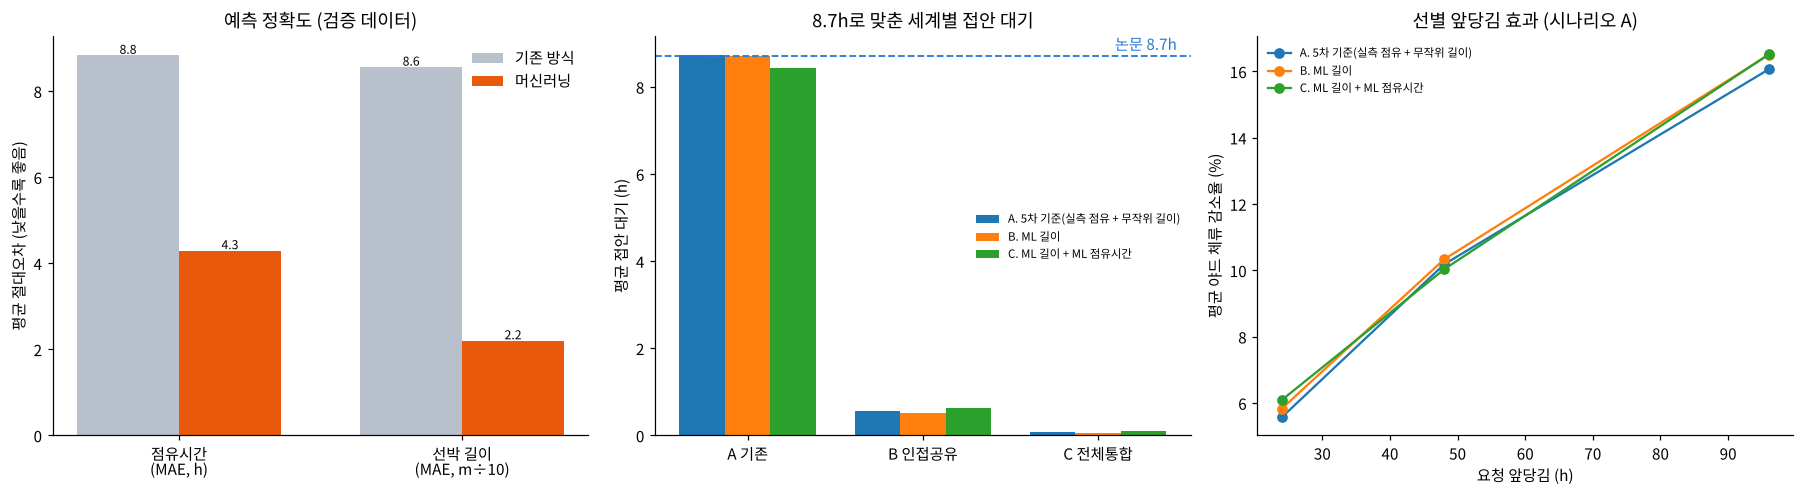

In [33]:
# 셀 33: [6차] 그림 - 예측 정확도, 세계별 접안 대기, 선별 앞당김 감소율
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
plt.rcParams["font.family"] = "Noto Sans CJK KR" if any("Noto Sans CJK KR" in f.name for f in fm.fontManager.ttflist) else "sans-serif"
fig, ax = plt.subplots(1, 3, figsize=(16.5, 4.6))
nm_s = {k: k.split(".")[0] for k in res6}             # 'A', 'B', 'C'
x = np.arange(3); wd = 0.26
for i, (nm, o) in enumerate(res6.items()):
    ax[1].bar(x + (i - 1) * wd, [np.mean(o["wait"][s]) for s in "ABC"], wd, label=nm)
ax[1].axhline(TARGET_WAIT_H, color="#2878d6", ls="--", lw=1.2); ax[1].text(2.45, TARGET_WAIT_H + 0.15, "논문 8.7h", color="#2878d6", ha="right")
ax[1].set_xticks(x); ax[1].set_xticklabels(["A 기존", "B 인접공유", "C 전체통합"]); ax[1].set_ylabel("평균 접안 대기 (h)"); ax[1].set_title("8.7h로 맞춘 세계별 접안 대기"); ax[1].legend(fontsize=7.5, frameon=False)
names = ["점유시간\n(MAE, h)", "선박 길이\n(MAE, m÷10)"]
vals_base = [ml_svc["기준(터미널 중앙값)"][0], ml_loa["무작위(현재 방식)"][0] / 10]
vals_ml = [ml_svc["그래디언트 부스팅"][0], ml_loa["그래디언트 부스팅"][0] / 10]
xx = np.arange(2)
ax[0].bar(xx - 0.18, vals_base, 0.36, color="#b8c0cc", label="기존 방식"); ax[0].bar(xx + 0.18, vals_ml, 0.36, color="#e8590c", label="머신러닝")
for j in range(2):
    ax[0].text(xx[j] - 0.18, vals_base[j], f"{vals_base[j]:.1f}", ha="center", va="bottom", fontsize=8); ax[0].text(xx[j] + 0.18, vals_ml[j], f"{vals_ml[j]:.1f}", ha="center", va="bottom", fontsize=8)
ax[0].set_xticks(xx); ax[0].set_xticklabels(names); ax[0].set_ylabel("평균 절대오차 (낮을수록 좋음)"); ax[0].set_title("예측 정확도 (검증 데이터)"); ax[0].legend(frameon=False)
for nm in res6:
    ys = [adv6[(adv6["세계"] == nm) & (adv6["정책"] == "선별") & (adv6["요청 앞당김(h)"] == a) & (adv6["시나리오"] == "A")]["감소율(%)"].iloc[0] for a in (24, 48, 96)]
    ax[2].plot([24, 48, 96], ys, marker="o", label=nm)
ax[2].set_xlabel("요청 앞당김 (h)"); ax[2].set_ylabel("평균 야드 체류 감소율 (%)"); ax[2].set_title("선별 앞당김 효과 (시나리오 A)"); ax[2].legend(fontsize=7.5, frameon=False)
for a_ in ax:
    a_.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


# 6차 요약 (머신러닝 예측모델을 넣은 8.7h 기준 시뮬레이션)

> **한 줄 결론.** 머신러닝 예측모델 2개(점유시간, 선박 길이)는 **입력의 정확도를 크게 높였지만 결론은 바꾸지 않았다.** 8.7h로 맞춘 세계에서 선별 앞당김의 야드 체류 감소율은 5차(10.2%)와 같은 수준(10.0~10.3%, 48h, 시나리오 A)이다. 즉 앞의 결과가 입력을 거칠게 잡아서 나온 것이 아님을 확인했다.

| 항목 | 기존 방식 | 머신러닝 |
|---|---|---|
| 점유시간 예측 오차 MAE (하반기 검증, h) | 8.83 | **4.29** |
| 점유시간 예측 R² | 0.108 | **0.563** |
| 선박 길이 예측 오차 MAE (선박 단위 검증, m) | 85.6 | **22.0** |
| 선박 길이 예측 R² | -0.65 | **0.82** |

| 세계 (모두 A 대기 8.7h에 맞춤) | A. 5차 기준 | B. ML 길이 | C. ML 길이 + ML 점유시간 |
|---|---|---|---|
| 점유시간 배율 m* | 1.160 | 1.160 | 1.201 |
| 평균 대기 A / B / C (h) | 8.72 / 0.56 / 0.09 | 8.71 / 0.51 / 0.07 | 8.44 / 0.62 / 0.11 |
| 선별 앞당김 감소율 A, 24/48/96h (%) | 5.6 / 10.2 / 16.1 | 5.8 / 10.3 / 16.5 | 6.1 / 10.0 / 16.5 |
| 전체 앞당김 감소율 A, 24/48/96h (%) | 3.4 / 6.1 / 8.7 | 3.4 / 6.2 / 8.8 | 3.3 / 5.6 / 9.5 |
| 선별 48h 다른 선박 지연 A / B / C (h) | 0.42 / 0.07 / 0.04 | 0.52 / 0.14 / 0.06 | 0.64 / 0.03 / 0.04 |


# 6차 방법

- **모델.** 그래디언트 부스팅 회귀(scikit-learn `HistGradientBoostingRegressor`). 이 환경에서 LightGBM 설치가 되지 않아 같은 계열 모델을 썼다.
- **(1) 점유시간 예측.** 특성은 터미널, 선사, 항로, 선박 길이·선폭·GT·DWT, 양하·적하 물량, 접안 예정의 달·요일·시간대이다. 작업 종료 시각처럼 접안 뒤에야 알 수 있는 값은 쓰지 않았다. 상반기로 학습해 하반기로 검증했다. 시뮬레이션에는 교차 예측(상반기 호출은 하반기로 학습한 모델, 하반기 호출은 상반기로 학습한 모델)을 입력했다.
- **(2) 선박 길이 보완.** 길이가 빈 300건(58척)은 선폭·GT·DWT도 비어 있고 같은 선박명의 다른 호출에도 길이가 없다. 그래서 터미널·선사·항로·물량만 특성으로 쓰고, 검증은 선박명 단위 5-겹으로 해서 처음 보는 선박을 맞히는 능력을 쟀다. 5차까지는 같은 터미널 길이 분포에서 무작위로 뽑았다.
- **세계 3개.** 각 세계에서 점유시간 배율 m을 이분 탐색해 A의 평균 대기를 논문의 8.7h로 맞춘 뒤, 5차와 같은 방식으로 A/B/C와 연결선 앞당김(전체, 선별)을 돌렸다. 세계 A는 무작위 길이 10회 반복이고, 세계 B와 C는 길이가 고정이라 1회 실행이다.


# 6차 결과 분석

- **예측모델의 정확도.** 점유시간은 오차가 절반으로(8.8h에서 4.3h) 줄었고 R²가 0.11에서 0.56이 됐다. 중요 특성은 적하·양하 물량과 항로였다. 선박 길이는 오차가 86m에서 22m로 줄었다.
- **결론은 같다.** 세 세계 모두에서 선별 앞당김 감소율은 48h에서 10.0~10.3%, 96h에서 16.1~16.5%이고, 통합(B, C)의 평균 대기는 0.1~0.6h로 A의 8.4~8.7h에서 크게 줄었다. 세계 간 차이(0.5%p 이내)는 B와 C가 1회 실행이라는 점을 고려하면 의미 있는 차이로 보지 않는다.
- **점유시간 예측을 쓰면 m이 커진다(1.16에서 1.20).** 예측값은 평균 쪽으로 모여서(표준편차 11.6h, 실제 13.7h) 긴 작업이 덜 반영되고, 같은 대기 8.7h를 만들려면 점유시간을 더 늘려야 하기 때문이다.
- **A의 한계는 그대로다.** 어느 세계에서든 A에서는 앞당김이 다른 선박을 지연시키고(선별 48h에서 0.4~0.6h) 요청 앞당김의 실현 비율이 82~88%로 떨어진다. B와 C는 99% 안팎이다.
- **정책 선별에는 ML이 필요 없다.** 4차에서 실현 비율을 예측하는 모델이 단순한 박스 수 순위와 같았고, 이번에도 선별 기준은 박스 수 규칙 그대로 두었다. 머신러닝은 시뮬레이션의 **입력(점유시간, 선박 길이)**에 쓰는 것이 유효했다.


# 6차 한계

- 점유시간 예측에 쓴 양하·적하 물량은 실제로는 접안 전에 계획값으로만 알 수 있다. 이 데이터의 물량이 계획값인지 실적값인지에 따라 실제 예측 성능은 낮아질 수 있다.
- 선박 길이 보완은 결측 300건(전체의 4%)에만 영향을 주므로 시뮬레이션 결과에 미치는 영향이 작다. 예측 평균(226m)이 알려진 선박 평균(258m)보다 낮아 작은 선박이 많다는 점은 확인했지만 정답은 알 수 없다.
- 세계 B와 C는 길이를 고정해 1회만 실행해서 불확실성 구간이 없다. 차이가 작은 비교(0.5%p 이내)는 해석하지 않는다.
- 8.7h 보정은 5차와 같은 가정(2026년 8월 평균, 점유시간 배율)에 의존한다.
- 모델은 그래디언트 부스팅 한 종류만 썼고, 하이퍼파라미터 탐색과 다른 모델(랜덤포레스트 등)과의 비교는 하지 않았다.
